In [118]:
# STFT FROM SCRATCH
# import
import numpy as np
from scipy.signal import stft as scipy_stft
import scipy
import matplotlib.pyplot as plt
from numpy.linalg import inv
from scipy.io.wavfile import read, write
import IPython

In [119]:
def compute_hop(nperseg, hop_fraction=0.25):
    """
    Calcule la taille du 'hop' (déplacement en échantillons) et renvoie aussi le recouvrement.

    Paramètres
    ----------
    nperseg : int
        Taille de la fenêtre en échantillons (doit être >= 1).
    hop_fraction : float
        Fraction du nperseg correspondant au hop.
        - Doit être strictement entre 0.0 et 1.0 (exclu).
        - hop_fraction = hop / nperseg.
        - Exemple : hop_fraction=0.25 -> hop = 0.25*nperseg -> overlap = 0.75 (75% recouvrement).

    Retour
    ------
    hop : int
        Nombre d'échantillons de déplacement entre trames (>= 1 et <= nperseg).
    overlap : float
        Fraction de recouvrement entre 0 et <1 (overlap = 1 - hop_fraction).
    """
    # validations
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop_fraction, (int, float)):
        raise ValueError("hop_fraction doit être un nombre (float).")
    hop_fraction = float(hop_fraction)

    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction doit être dans l'intervalle (0.0, 1.0) une fraction quoi. "
                         "Exemples : 0.5 -> 50pourencent overlap (hop = nperseg*0.5), "
                         "0.25 -> 75% overlap (hop = nperseg*0.25).")

    # calcul du hop (arrondi au plus proche entiers)
    hop = int(round(nperseg * hop_fraction))

    # protections : s'assurer que hop est dans [1, nperseg]
    if hop < 1:
        hop = 1
    if hop > nperseg:
        hop = nperseg

    overlap = 1.0 - (hop / float(nperseg))

    return hop, overlap


In [120]:
# Framing
import numpy as np

def framing(x, nperseg, hop):
    """
    Découpe le signal 1D `x` en trames (frames) successives.

    Paramètres
    ----------
    x : ndarray 1D
        Signal d'entrée (supposée mono).
    nperseg : int
        Taille de chaque frame en échantillons (>=1).
    hop : int
        Déplacement en échantillons entre le début de deux frames (>=1, <= nperseg).

    Remarques
    ---------
    - Cette version simplifiée FORCE le padding de la fin du signal (padding constant à zéro)
      afin que la dernière frame soit complète : on n'accepte plus d'options pour le padding.
      
    - Le pad_mode est fixé à 'constant' (zéros).
    - Le comportement garantit au moins une frame si le signal est plus court que nperseg.
    """

    # validations simples
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop, int) or hop < 1:
        raise ValueError("hop doit être un entier >= 1.")
    if hop > nperseg:
        raise ValueError("hop ne peut pas être supérieur à nperseg.")
    if x.ndim != 1:
        raise ValueError("x doit être un tableau 1D (signal mono).")

    N = len(x)
    if N == 0:
        return np.zeros((0, nperseg), dtype=x.dtype), np.zeros((0,), dtype=int)

    # --- calcul du nombre de frames (padding forcé à la fin, pad_mode='constant') ---
    # on autorise la dernière fenêtre à démarrer avant la fin et on complète si nécessaire
    n_frames_calc = int(np.floor((N - nperseg) / float(hop))) + 1
    # garantir au moins 1 frame (cas len(x) < nperseg)
    n_frames = max(1, n_frames_calc)

    # indices de départ
    starts = np.arange(n_frames) * hop

    # padding constant à la fin si nécessaire (pad_mode = 'constant')
    last_needed = starts[-1] + nperseg
    if last_needed > N:
        pad_len = last_needed - N
        x_padded = np.pad(x, (0, pad_len), mode='constant')
    else:
        x_padded = x

    # construire les frames
    frames = np.empty((n_frames, nperseg), dtype=x_padded.dtype)
    for i, s in enumerate(starts):
        frames[i, :] = x_padded[s : s + nperseg]

    return frames, starts


In [121]:
# la forme de notre fenetre qu'on va faire glisser sur le signal
def get_window(window_name="hann", nperseg=1024):
    """
    Génère une fenêtre temps de longueur `nperseg`.

    Paramètres
    ----------
    window_name : str
        Nom de la fenêtre souhaitée (insensible à la casse).
        Dans notre projet on n'utilise QUE :
            - 'hann' (recommandé pour STFT/ISTFT, respecte COLA avec hop = nperseg/2)

        Les autres fenêtres sont supprimées car :
            - 'rect' provoque des fuites spectrales
            - 'hamming', 'blackman', 'bartlett' compliquent la reconstruction
            - 'kaiser' inutile ici et nécessite un paramètre β
    nperseg : int
        Longueur de la fenêtre en échantillons (>= 1).

    Retour
    ------
    w : ndarray, shape (nperseg,)
        Vecteur fenêtre.

    Remarques / recommandations
    ---------------------------
    - 'hann' est un excellent compromis pour STFT et ISTFT.
      Avec hop = nperseg/2 → condition COLA vérifiée.
      (somme_k w[n - k*hop] = C)
    """

    # validations d'entrée
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")

    # accepter seulement 'hann' qui est suffisant (je pense)
    wn = str(window_name).lower()
    if wn not in ('hann', 'hanning'):
        raise ValueError(
            "Seule la fenêtre 'hann' est supportée dans notre implémentation simplifiée."
        )

    
    if nperseg > 1:
        n = np.arange(nperseg)
        w = 0.5 - 0.5 * np.cos(2.0 * np.pi * n / (nperseg - 1))
    else:
        w = np.array([1.0])

    return w.astype(float)


In [122]:
def apply_window(frames, window):
    """
    Applique une fenêtre à chaque trame.

    Paramètres
    ----------
    frames : ndarray (n_frames, nperseg)
        Trames du signal
    window : ndarray (nperseg,)
        Vecteur fenêtre

    Retour
    ------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (element-wise multiplication)
    
    Exemple
    -------
    >>> frames = np.array([[1, 2, 3], [4, 5, 6]])
    >>> window = np.array([0.5, 1.0, 0.5])
    >>> apply_window(frames, window)
    array([[0.5, 2. , 1.5],
           [2. , 5. , 3. ]])
    """
    # Validation des dimensions
    if frames.ndim != 2:
        raise ValueError(f"frames doit être 2D, shape reçu: {frames.shape}")
    if window.ndim != 1:
        raise ValueError(f"window doit être 1D, shape reçu: {window.shape}")
    if frames.shape[1] != window.shape[0]:
        raise ValueError(
            f"Dimension incompatible: frames.shape[1]={frames.shape[1]} "
            f"mais window.shape[0]={window.shape[0]}"
        )
    
    # Multiplication élément par élément (broadcasting)
    return frames * window

In [123]:
def fft_frames(windowed_frames, nfft=None, fs=1.0):
    """
    Applique la FFT réelle (rFFT) à chaque trame fenêtrée.

    Paramètres
    ----------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (signal réel).
    nfft : int ou None
        Taille de la FFT. Si None, nfft = nperseg.
        Si nfft > nperseg, zero-padding est appliqué.
    fs : float
        Fréquence d'échantillonnage en Hz (pour calculer les fréquences).
        Par défaut 1.0 (fréquences normalisées).

    Retour
    ------
    STFT : ndarray complex (n_frames, n_freq_bins)
        Transformée de Fourier par trame.
        n_freq_bins = nfft//2 + 1 (rFFT pour signaux réels).
    freqs : ndarray (n_freq_bins,)
        Fréquences en Hz correspondant aux bins de fréquence.

    Notes
    -----
    - Utilise np.fft.rfft() qui est optimisé pour les signaux réels.
    - n_freq_bins = nfft//2 + 1 (ex: nfft=1024 → 513 bins de fréquence).
    - La fréquence de Nyquist est fs/2 (incluse si nfft est pair).
    """
    # Validation des entrées
    if windowed_frames.ndim != 2:
        raise ValueError(f"windowed_frames doit être 2D, shape reçu: {windowed_frames.shape}")
    
    n_frames, nperseg = windowed_frames.shape
    
    # Déterminer nfft
    if nfft is None:
        nfft = nperseg
    elif nfft < nperseg:
        raise ValueError(f"nfft ({nfft}) ne peut pas être < nperseg ({nperseg})")
    elif nfft <= 0:
        raise ValueError(f"nfft doit être > 0, reçu: {nfft}")
    
    if fs <= 0:
        raise ValueError(f"fs doit être > 0, reçu: {fs}")
    
    # Appliquer la FFT réelle (rfft) sur chaque trame
    # axis=1 : FFT le long des colonnes (pour chaque trame)
    STFT = np.fft.rfft(windowed_frames, n=nfft, axis=1) # supposé 1d
    
    # np.fft.rfftfreq(nfft, d=1/fs) donne les fréquences pour un rfft
    freqs = np.fft.rfftfreq(nfft, d=1.0/fs)
    
    return STFT, freqs

In [124]:
def magnitude_or_power(STFT, kind="magnitude"):
    """
    Convertit la STFT complexe en magnitude ou puissance.
    """
    if kind == "magnitude":
        return np.abs(STFT)
    elif kind == "power":
        return np.abs(STFT) ** 2
    else:
        raise ValueError("kind doit être 'magnitude' ou 'power'")

In [125]:
def stft(
    x,
    fs,
    nperseg,
    window="hann",
    hop_fraction=0.25,       # la partie de la fenetre qui correspond au hop cad : hop_fraction = hop / nperseg
    nfft=None,
    output="magnitude",      # "magnitude" | "power" | "complex"
    keep_freq_max=None,      # float Hz or None (pour couper la frequence, genre afficher jusqu'a f_lim)
    normalize=False,         # bool : normaliser M par sa valeur max
    scipy_scale=True,
    save_path=None,          # str or None : chemin pour save_matrix()
    visualize=False,         # bool : appeler visualize_spectrogram()
    return_extra=False,       # bool : retourne frames, window, STFT en plus
    scipy_compatible=True
):
    """
    STFT - fonction orchestration (pipeline STFT 'from scratch').

    Cette fonction coordonne les étapes :
      1) calcul du hop à partir de nperseg et hop_fraction
      2) framing (découpage du signal en trames)
      3) génération de la fenêtre (window)
      4) fenêtrage des trames
      5) FFT frame-by-frame (avec éventuel zero-padding nfft)
      6) conversion en magnitude ou power (ou renvoyer STFT complexe)
      7) cropping fréquentiel optionnel (keep_freq_max)
      8) normalisation optionnelle
      9) sauvegarde / visualisation / retour

    Paramètres attendus (résumé) :
      - x : ndarray 1D (signal)
      - fs : int (échantillonnage en Hz)
      - nperseg : int (taille fenêtre en échantillons)
      - window : str or callable (nom de fenêtre, ex "hann")
      - hop_fraction : float dans (0,1) . Exemple 0.25 -> 75% overlap
      - nfft : int ou None. Si None, nfft = max(nperseg, 2048)
      - output : "magnitude", "power" ou "complex"
      - keep_freq_max : fréquence max à conserver (Hz) ou None
      - normalize : si True, M /= M.max()
      - save_path : si fourni, appelle save_matrix(M, freqs, times, meta, save_path)
      - visualize : si True, appelle visualize_spectrogram(M, freqs, times, f_lim=keep_freq_max_or_default)
      - return_extra : si True, retourne (M, freqs, times, meta, extras_dict)

    Retours :
      - si return_extra == False :
          (M, freqs, times, meta)
      - si return_extra == True :
          (M, freqs, times, meta, {"frames": frames, "window": window_vec, "STFT": STFT})
      - Convention de forme :
          M : ndarray shape (n_freq_bins, n_time_frames)  # recommandé freq x time
          freqs : ndarray length n_freq_bins (Hz)
          times : ndarray length n_time_frames (s)
          meta : dict (fs, nperseg, hop, nfft, window_name, output, keep_freq_max, normalize)

    Remarques d'implémentation :
      - Cette fonction suppose l'existence des helpers :
        compute_hop(nperseg, hop_fraction) -> int hop
        framing(x, nperseg, hop) -> frames (n_frames, nperseg)
        get_window(window_name, nperseg) -> window_vec (nperseg,)
        apply_window(frames, window_vec) -> windowed_frames
        fft_frames(windowed_frames, nfft) -> STFT (n_frames, n_freqs), freqs (n_freqs,)
        magnitude_or_power(STFT, kind="magnitude"|"power") -> M (n_freqs, n_frames)
        save_matrix(M, freqs, times, meta, path)
        visualize_spectrogram(M, freqs, times, f_lim)
      - times are computed as the center times of each frame:
          frame_center_sample = first_frame_start + frame_index * hop + nperseg/2
          time = frame_center_sample / fs
      - STFT returned by fft_frames is expected shape (n_frames, n_freqs) (time major).
      - stft() converts that to M with shape (n_freqs, n_frames) for convention freq x time.

    """
    # ---------------------------
    # 1) Validation & defaults
    # ---------------------------
    

    if x is None:
        raise ValueError("Signal x is None")
    if x.ndim != 1:
        raise ValueError("Signal x must be 1D (mono). Convert to mono before calling stft().")
    if nperseg <= 0:
        raise ValueError("nperseg must be a positive integer.")
    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction must be in (0,1). Example: 0.25 for 75% overlap.")

    if nfft is None:
        nfft = nperseg

    # ---------------------------
    # 2) compute hop
    # ---------------------------
    hop, overlap = compute_hop(nperseg, hop_fraction)  # retourne (hop, overlap)
    # On garde seulement hop pour le reste, overlap sera ajouté dans meta

    # ---------------------------
    # 3) framing
    # ---------------------------
    frames, starts = framing(x, nperseg=nperseg, hop=hop)  # shape (n_frames, nperseg)
    n_frames = frames.shape[0]

    # ---------------------------
    # 4) window generation & apply
    # ---------------------------
    window_vec = get_window(window, nperseg)     # shape (nperseg,)
    windowed = apply_window(frames, window_vec)  # shape (n_frames, nperseg)

    # ---------------------------
    # 5) FFT par frame
    # ---------------------------
    STFT, freqs = fft_frames(windowed, nfft=nfft, fs=fs)
    # STFT expected shape: (n_frames, n_freqs), freqs shape (n_freqs,)

    # ---------------------------
    # 6) magnitude/power/keep complex
    # ---------------------------
    if output == "complex":
        M_complex = STFT.T  
        M = None
        scale_factor = nperseg / 2.0
    elif output in ("magnitude", "power"):
        M_tmp = magnitude_or_power(STFT, kind=output)  
        
        if scipy_scale:
            if output == "magnitude":
                # Pour magnitude: diviser par nperseg/2
                scale_factor = nperseg / 2.0
            else:  # power
                # Pour power: diviser par (nperseg/2)²
                scale_factor = (nperseg / 2.0) ** 2
                
            M_tmp = M_tmp / scale_factor
            
        # Ensure convention freq x time
        if M_tmp.shape[0] == STFT.shape[0]:
            # If helper returned time-major (n_frames, n_freqs), transpose time et freq sont inversées en gros
            M = M_tmp.T
        else:
            M = M_tmp
    else:
        raise ValueError("output must be one of 'magnitude', 'power', 'complex'")

    # ---------------------------
    # 7) time vector (frame centers)
    # ---------------------------
    # first frame start sample est starts[0] (pas forcément 0)
    # frame_centers_samples = (np.arange(n_frames) * hop) + (nperseg / 2.0)
    frame_centers_samples = starts + (nperseg / 2.0)  
    times = frame_centers_samples / float(fs)   # seconds

    # ---------------------------
    # 8) cropping frequency dimension (optional)
    # ---------------------------
    if keep_freq_max is not None:
        # freqs is length n_freqs (Hz)
        freq_mask = freqs <= float(keep_freq_max)
        freqs_sel = freqs[freq_mask]
        
        if output == "complex":
            M_complex = M_complex[freq_mask, :] if M_complex is not None else None
        else:
            M = M[freq_mask, :] if M is not None else None
    else:
        freqs_sel = freqs

    # ---------------------------
    # 9) normalization (only for magnitude/power)
    # ---------------------------
    # CORRECTION: Ajout de la normalisation pour magnitude/power
    if normalize and output != "complex" and M is not None:
        M_max = M.max()
        if M_max > 0:
            M = M / M_max

    # ---------------------------
    # 10) metadata assembly
    # ---------------------------
    # CORRECTION: Ajout de 'overlap' dans les métadonnées
    meta = {
        "fs": int(fs),
        "nperseg": int(nperseg),
        "hop": int(hop),
        "hop_fraction": float(hop_fraction),
        "overlap": float(overlap),  # CORRECTION: Ajouté
        "nfft": int(nfft),
        "window": str(window),
        "output": str(output),
        "keep_freq_max": (float(keep_freq_max) if keep_freq_max is not None else None),
        "normalize": bool(normalize),
        "starts": starts.tolist()  # CORRECTION: Ajouté pour debug/reconstruction
    }

    # ---------------------------
    # 11) save & visualize (optional)
    # ---------------------------
    # CORRECTION: Gestion conditionnelle de save_path et visualize
    if save_path is not None:
        # À implémenter: save_matrix(M, freqs_sel, times, meta, save_path)
        pass
        
    if visualize:
        # À implémenter: visualize_spectrogram(M, freqs_sel, times, f_lim=keep_freq_max)
        pass

    # ---------------------------
    # 12) return values
    # ---------------------------
    if return_extra:
        extras = {
            "frames": frames,
            "window": window_vec,
            "STFT": STFT,  
            "starts": starts
        }
        if output == "complex":
            # return complex STFT in the place of M 
            return M_complex, freqs_sel, times, meta, extras
        return M, freqs_sel, times, meta, extras

    # no extras
    if output == "complex":
        return M_complex, freqs_sel, times, meta
    return M, freqs_sel, times, meta

ANALYSE DU FICHIER AUDIO
Fichier: piano_mix.wav
Taux d'échantillonnage: 44100 Hz
Nombre d'échantillons: 154028
Durée: 3.49 secondes
Type de données: int16
Shape: (154028,)

Paramètres STFT:
  nperseg: 512
  hop_fraction: 0.25 (hop: 128 échantillons)
  noverlap (pour SciPy): 384

NOTRE STFT
Shape: (257, 1200) (freqs × time)
Freqs: 257 bins, 0.0-22050.0 Hz
Times: 1200 frames, 0.006-3.486 s

SCIPY STFT
Shape: (257, 1200) (freqs × time)
Freqs: 257 bins, 0.0-22050.0 Hz
Times: 1200 frames, 0.006-3.486 s

COMPARAISON
✓ Shapes identiques!
  Différence moyenne: 0.391002
  Différence max: 64.382840
  Corrélation: 0.999997


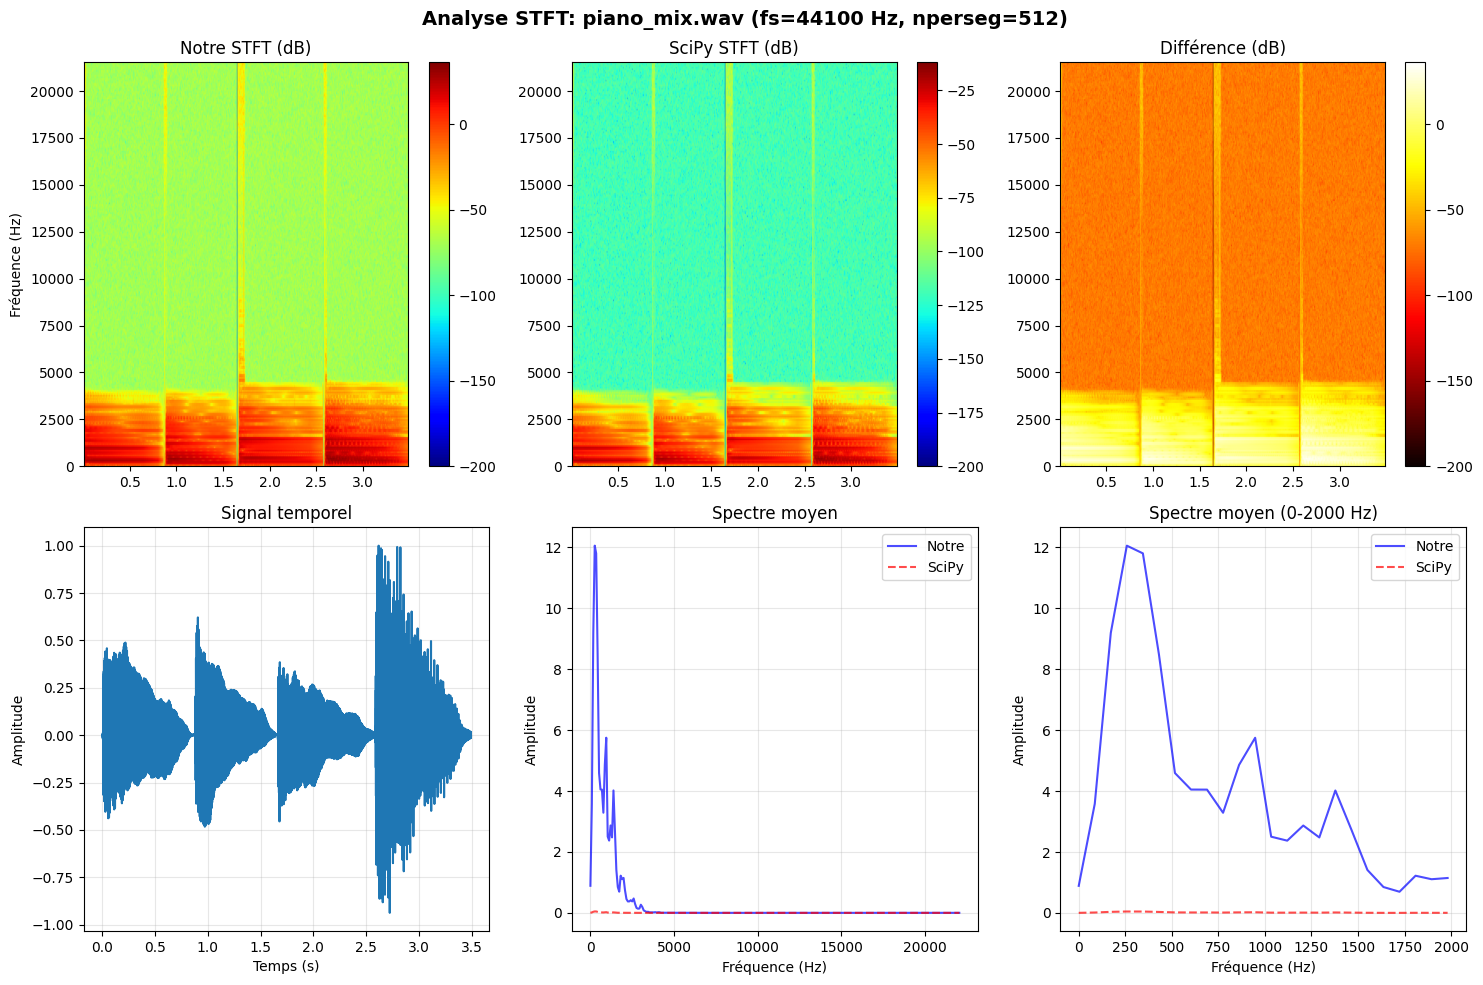

In [126]:

fs, x = scipy.io.wavfile.read('son/piano_mix.wav')

print("=" * 60)
print("ANALYSE DU FICHIER AUDIO")
print("=" * 60)
print(f"Fichier: piano_mix.wav")
print(f"Taux d'échantillonnage: {fs} Hz")
print(f"Nombre d'échantillons: {len(x)}")
print(f"Durée: {len(x)/fs:.2f} secondes")
print(f"Type de données: {x.dtype}")
print(f"Shape: {x.shape}")

# Normaliser le signal mono (1d)
x = x.astype(np.float32) / np.max(np.abs(x))


# -------------------------------------------------
# 2. Paramètres STFT communs
# -------------------------------------------------
nperseg = 512
hop_fraction = 0.25  # 75% overlap
hop = int(nperseg * hop_fraction)
noverlap = nperseg - hop  # Pour SciPy

print(f"\nParamètres STFT:")
print(f"  nperseg: {nperseg}")
print(f"  hop_fraction: {hop_fraction} (hop: {hop} échantillons)")
print(f"  noverlap (pour SciPy): {noverlap}")

# -------------------------------------------------
# 3. NOTRE STFT
# -------------------------------------------------
print(f"\n{'='*40}")
print("NOTRE STFT")
print(f"{'='*40}")

M_our, freqs_our, times_our, meta_our = stft(
    x, fs, nperseg, 
    window='hann',
    hop_fraction=hop_fraction,
    output="complex",
    scipy_compatible=True  # Important pour la cohérence
)

print(f"Shape: {M_our.shape} (freqs × time)")
print(f"Freqs: {len(freqs_our)} bins, {freqs_our[0]:.1f}-{freqs_our[-1]:.1f} Hz")
print(f"Times: {len(times_our)} frames, {times_our[0]:.3f}-{times_our[-1]:.3f} s")

# Magnitude pour visualisation
M_mag_our = np.abs(M_our)

# -------------------------------------------------
# 4. SCIPY STFT (pour comparaison)
# -------------------------------------------------
print(f"\n{'='*40}")
print("SCIPY STFT")
print(f"{'='*40}")

freqs_sp, times_sp, M_sp = scipy_stft(
    x, fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap,  # IMPORTANT: même overlap que notre STFT
    nfft=nperseg,
    return_onesided=True,
    boundary=None,
    padded=False
)

print(f"Shape: {M_sp.shape} (freqs × time)")
print(f"Freqs: {len(freqs_sp)} bins, {freqs_sp[0]:.1f}-{freqs_sp[-1]:.1f} Hz")
print(f"Times: {len(times_sp)} frames, {times_sp[0]:.3f}-{times_sp[-1]:.3f} s")

M_mag_sp = np.abs(M_sp)

## -------------------------------------------------
# 5. COMPARAISON
# -------------------------------------------------
print(f"\n{'='*40}")
print("COMPARAISON")
print(f"{'='*40}")

if M_mag_our.shape == M_mag_sp.shape:
    print("✓ Shapes identiques!")
    
    # Différence
    diff = np.abs(M_mag_our - M_mag_sp)
    print(f"  Différence moyenne: {diff.mean():.6f}")
    print(f"  Différence max: {diff.max():.6f}")
    print(f"  Corrélation: {np.corrcoef(M_mag_our.flatten(), M_mag_sp.flatten())[0,1]:.6f}")
else:
    print(f"✗ Shapes différentes:")
    print(f"  Notre: {M_mag_our.shape}")
    print(f"  SciPy: {M_mag_sp.shape}")

# -------------------------------------------------
# 6. VISUALISATION
# -------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Notre spectrogramme (magnitude)
ax1 = axes[0, 0]
im1 = ax1.imshow(20 * np.log10(M_mag_our[:250] + 1e-10), 
                aspect='auto', origin='lower', 
                extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                cmap='jet')
ax1.set_title('Notre STFT (dB)')
ax1.set_ylabel('Fréquence (Hz)')
plt.colorbar(im1, ax=ax1)

# SciPy spectrogramme
ax2 = axes[0, 1]
im2 = ax2.imshow(20 * np.log10(M_mag_sp[:250] + 1e-10), 
                aspect='auto', origin='lower',
                extent=[times_sp[0], times_sp[-1], freqs_sp[0], freqs_sp[250]],
                cmap='jet')
ax2.set_title('SciPy STFT (dB)')
plt.colorbar(im2, ax=ax2)

# Différence
if M_mag_our.shape == M_mag_sp.shape:
    ax3 = axes[0, 2]
    diff_dB = 20 * np.log10(diff[:250] + 1e-10)
    im3 = ax3.imshow(diff_dB, 
                    aspect='auto', origin='lower',
                    extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                    cmap='hot')
    ax3.set_title('Différence (dB)')
    plt.colorbar(im3, ax=ax3)

# Signal temporel
ax4 = axes[1, 0]
time_axis = np.arange(len(x)) / fs
ax4.plot(time_axis, x)
ax4.set_title('Signal temporel')
ax4.set_xlabel('Temps (s)')
ax4.set_ylabel('Amplitude')
ax4.grid(True, alpha=0.3)

# Spectre moyen
ax5 = axes[1, 1]
spectrum_our = M_mag_our.mean(axis=1)
spectrum_sp = M_mag_sp.mean(axis=1)
ax5.plot(freqs_our, spectrum_our, 'b-', label='Notre', alpha=0.7)
ax5.plot(freqs_sp, spectrum_sp, 'r--', label='SciPy', alpha=0.7)
ax5.set_title('Spectre moyen')
ax5.set_xlabel('Fréquence (Hz)')
ax5.set_ylabel('Amplitude')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Zoom sur les basses fréquences (pour la musique)
ax6 = axes[1, 2]
freq_limit = 2000  # 2 kHz
freq_mask = freqs_our <= freq_limit
ax6.plot(freqs_our[freq_mask], spectrum_our[freq_mask], 'b-', label='Notre', alpha=0.7)
ax6.plot(freqs_sp[freq_mask], spectrum_sp[freq_mask], 'r--', label='SciPy', alpha=0.7)
ax6.set_title(f'Spectre moyen (0-{freq_limit} Hz)')
ax6.set_xlabel('Fréquence (Hz)')
ax6.set_ylabel('Amplitude')
ax6.legend()
ax6.grid(True, alpha=0.3)

plt.suptitle(f'Analyse STFT: piano_mix.wav (fs={fs} Hz, nperseg={nperseg})', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [127]:
##############################################################################################################################
#    NMF
##############################################################################################################################
def NMF_First_Method(M, S,  epsilon = 0.06, MAX_iter = 1000): 
    
     
    counter = 0
   
    cost_function = []
    beta_divergence = 1
    
    K, N = np.shape(M)
    
    # Initialisation of W and H matrices : The initialization is generally random
    D = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    A = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    last_betha = beta_divergence + epsilon
    while abs(last_betha - beta_divergence) > epsilon and counter <= MAX_iter:
        
        # Update of W and H
        last_betha = beta_divergence
        A = (inv((D.T@D)))@D.T@M
        A=np.where(A<0,0,A)
        D = (M@A.T)@(inv(A@A.T))
        D=np.where(D<0,0,D)
        

        # Compute cost function
        beta_divergence =  ((np.linalg.norm(M-D@A))**2)
        
        cost_function.append( beta_divergence )
        counter += 1
    print(cost_function)
       
    return A,D,cost_function

[np.float64(145255.84827144223), np.float64(95817.54785955079), np.float64(90688.32798294935), np.float64(89004.29021225851), np.float64(88180.91473475994), np.float64(87737.41888308736), np.float64(87486.70238778598), np.float64(87332.01617754342), np.float64(87227.92918359999), np.float64(87151.92958326585), np.float64(87093.33409803823), np.float64(87046.65350371882), np.float64(87008.58042864627), np.float64(86976.60832548513), np.float64(86949.4534046468), np.float64(86926.15098055688), np.float64(86906.01218990915), np.float64(86888.42356416468), np.float64(86872.88988446219), np.float64(86859.07234705983), np.float64(86846.45799643846), np.float64(86834.75152055288), np.float64(86823.81822896887), np.float64(86813.72978166604), np.float64(86804.76026948153), np.float64(86796.40635451392), np.float64(86788.3341523957), np.float64(86780.44766797086), np.float64(86772.72334482454), np.float64(86765.16478317638), np.float64(86757.83111262445), np.float64(86750.69768246078), np.float

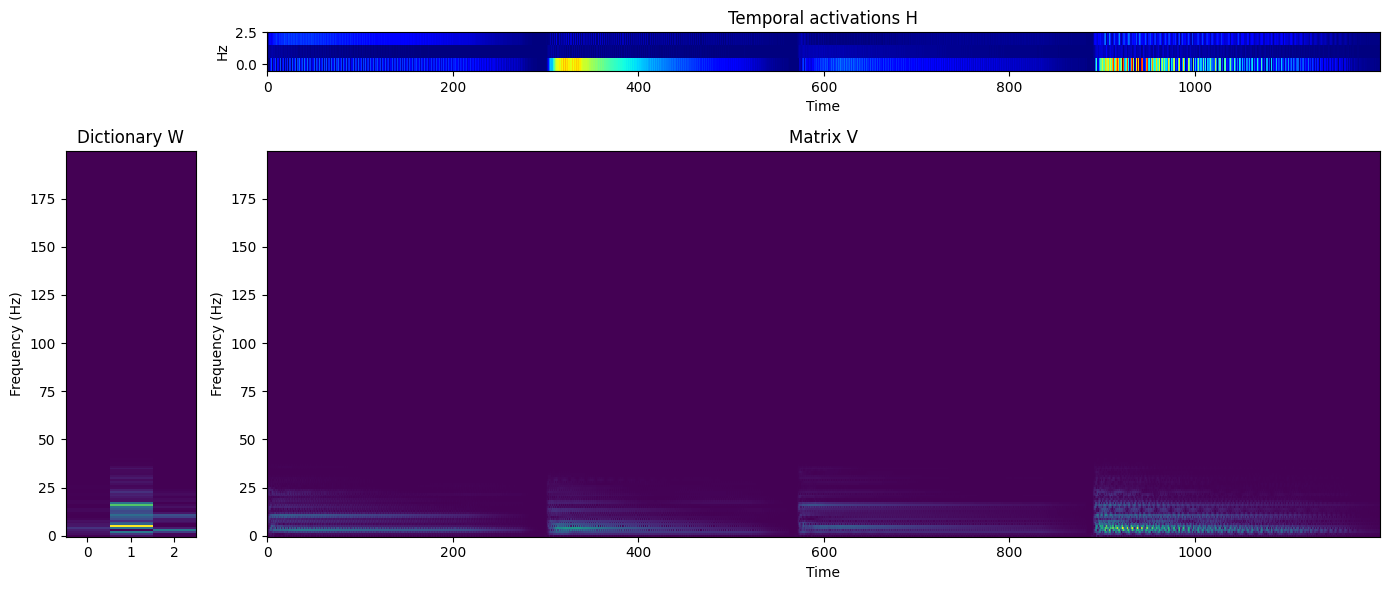

Text(0, 0.5, 'Beta Divergence for beta = 2 ')

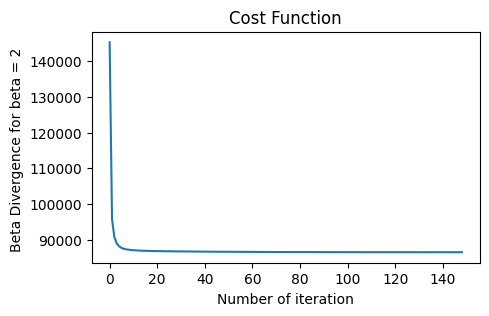

In [128]:
S = 3

A, D, cost_function = NMF_First_Method(M_mag_our, S)

# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(A, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(D[:200],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(M_mag_our)[:200], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# COST FUNCTION
# Ploting the cost function
plt.figure(figsize=(5,3))
plt.plot(cost_function)
plt.title("Cost Function")
plt.xlabel("Number of iteration")
plt.ylabel(f"Beta Divergence for beta = {2} ")


In [129]:
def NMF_Second_Method(M, S,  epsilon = 0.006, MAX_iter = 5000): 
    
    #np.random.seed(int(time.time())) 
    counter = 0
   
    #cost_function = []
    beta_divergence = 1
    
    K, N = np.shape(M)
    cost_function = []
    # Initialisation of W and H matrices : The initialization is generally random
    D = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    A = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    last_betha = beta_divergence + epsilon
    while abs(last_betha - beta_divergence) >= epsilon and counter <= MAX_iter:
        last_betha = beta_divergence
        # Update of W and H
        numerator_A = D.T @ M
        denominator_A = D.T @ D @ A
        
        # On ajoute 1e-9 pour éviter la division par zéro si le dénominateur est nul
        A = A * (numerator_A / (denominator_A + 1e-9))

        numerator_D = M @ A.T
        denominator_D = D @ A @ A.T
        
        D = D * (numerator_D / (denominator_D + 1e-9))
        beta_divergence =  (np.linalg.norm(M-D@A))
        #print(beta_divergence)
        cost_function.append( beta_divergence )
        counter += 1
        """if counter % 40 == 0:
            print(f'{abs(last_betha - beta_divergence) = }')
    print(f'{counter = }')"""
    return A,D,cost_function

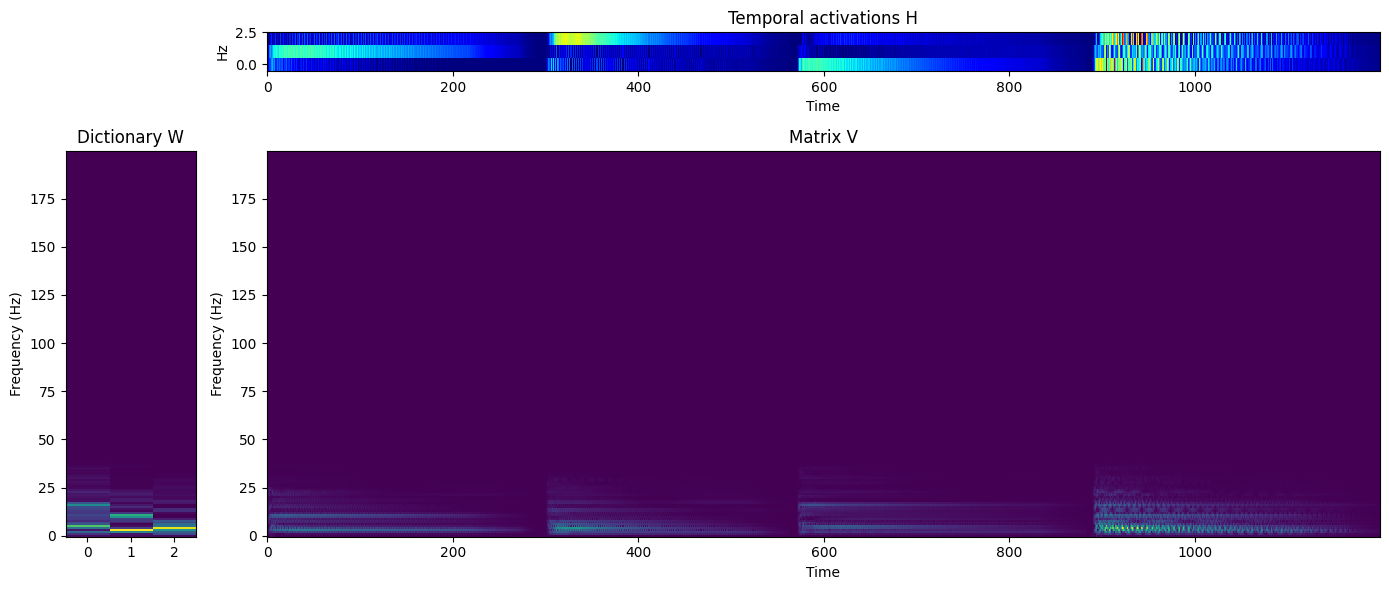

Text(0, 0.5, 'Beta Divergence for beta = 2 ')

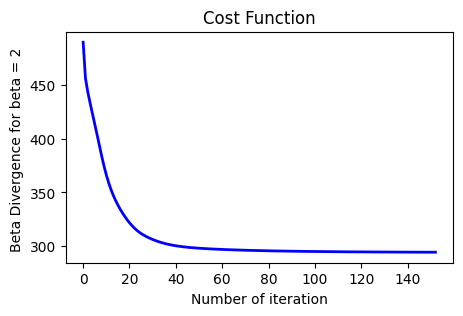

In [130]:
S = 3

A, D, cost_function = NMF_Second_Method(M_mag_our, S)

# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(A, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(D[:200],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(M_mag_our)[:200], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# COST FUNCTION
# Ploting the cost function
plt.figure(figsize=(5,3))
plt.plot(cost_function, color='b', linewidth=2, label='Beta Divergence')
plt.title("Cost Function")
plt.xlabel("Number of iteration")
plt.ylabel(f"Beta Divergence for beta = {2} ")


NMF AVEC SCIKIT-LEARN
Matrice V (spectrogramme):
  Shape: (257, 1200)
  Taille: 257 freq × 1200 time
  Valeurs: min=0.000000, max=64.635739, mean=0.392537
  Normalisé: max=1.0

NMF avec k=2 composantes
Entraînement en cours...
✓ Entraînement terminé
  W shape: (257, 2)
  H shape: (2, 1200)
  Reconstruction error: 5.424330
  Itérations: 200

NMF avec k=3 composantes
Entraînement en cours...
✓ Entraînement terminé
  W shape: (257, 3)
  H shape: (3, 1200)
  Reconstruction error: 4.545904
  Itérations: 200

NMF avec k=4 composantes
Entraînement en cours...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


✓ Entraînement terminé
  W shape: (257, 4)
  H shape: (4, 1200)
  Reconstruction error: 3.821477
  Itérations: 138

NMF avec k=5 composantes
Entraînement en cours...
✓ Entraînement terminé
  W shape: (257, 5)
  H shape: (5, 1200)
  Reconstruction error: 3.258770
  Itérations: 200

ANALYSE DES RÉSULTATS

Erreur de reconstruction par nombre de composantes:
  k=2: erreur = 5.424330
  k=3: erreur = 4.545904
  k=4: erreur = 3.821477
  k=5: erreur = 3.258770

Meilleur k: 5 (erreur: 3.258770)

SÉPARATION DES SOURCES (k=5)
Source 1: shape=(257, 1200), min=0.000000, max=0.484773
Source 2: shape=(257, 1200), min=0.000000, max=0.548248
Source 3: shape=(257, 1200), min=0.000000, max=0.294909
Source 4: shape=(257, 1200), min=0.000000, max=0.483414
Source 5: shape=(257, 1200), min=0.000000, max=0.690518


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


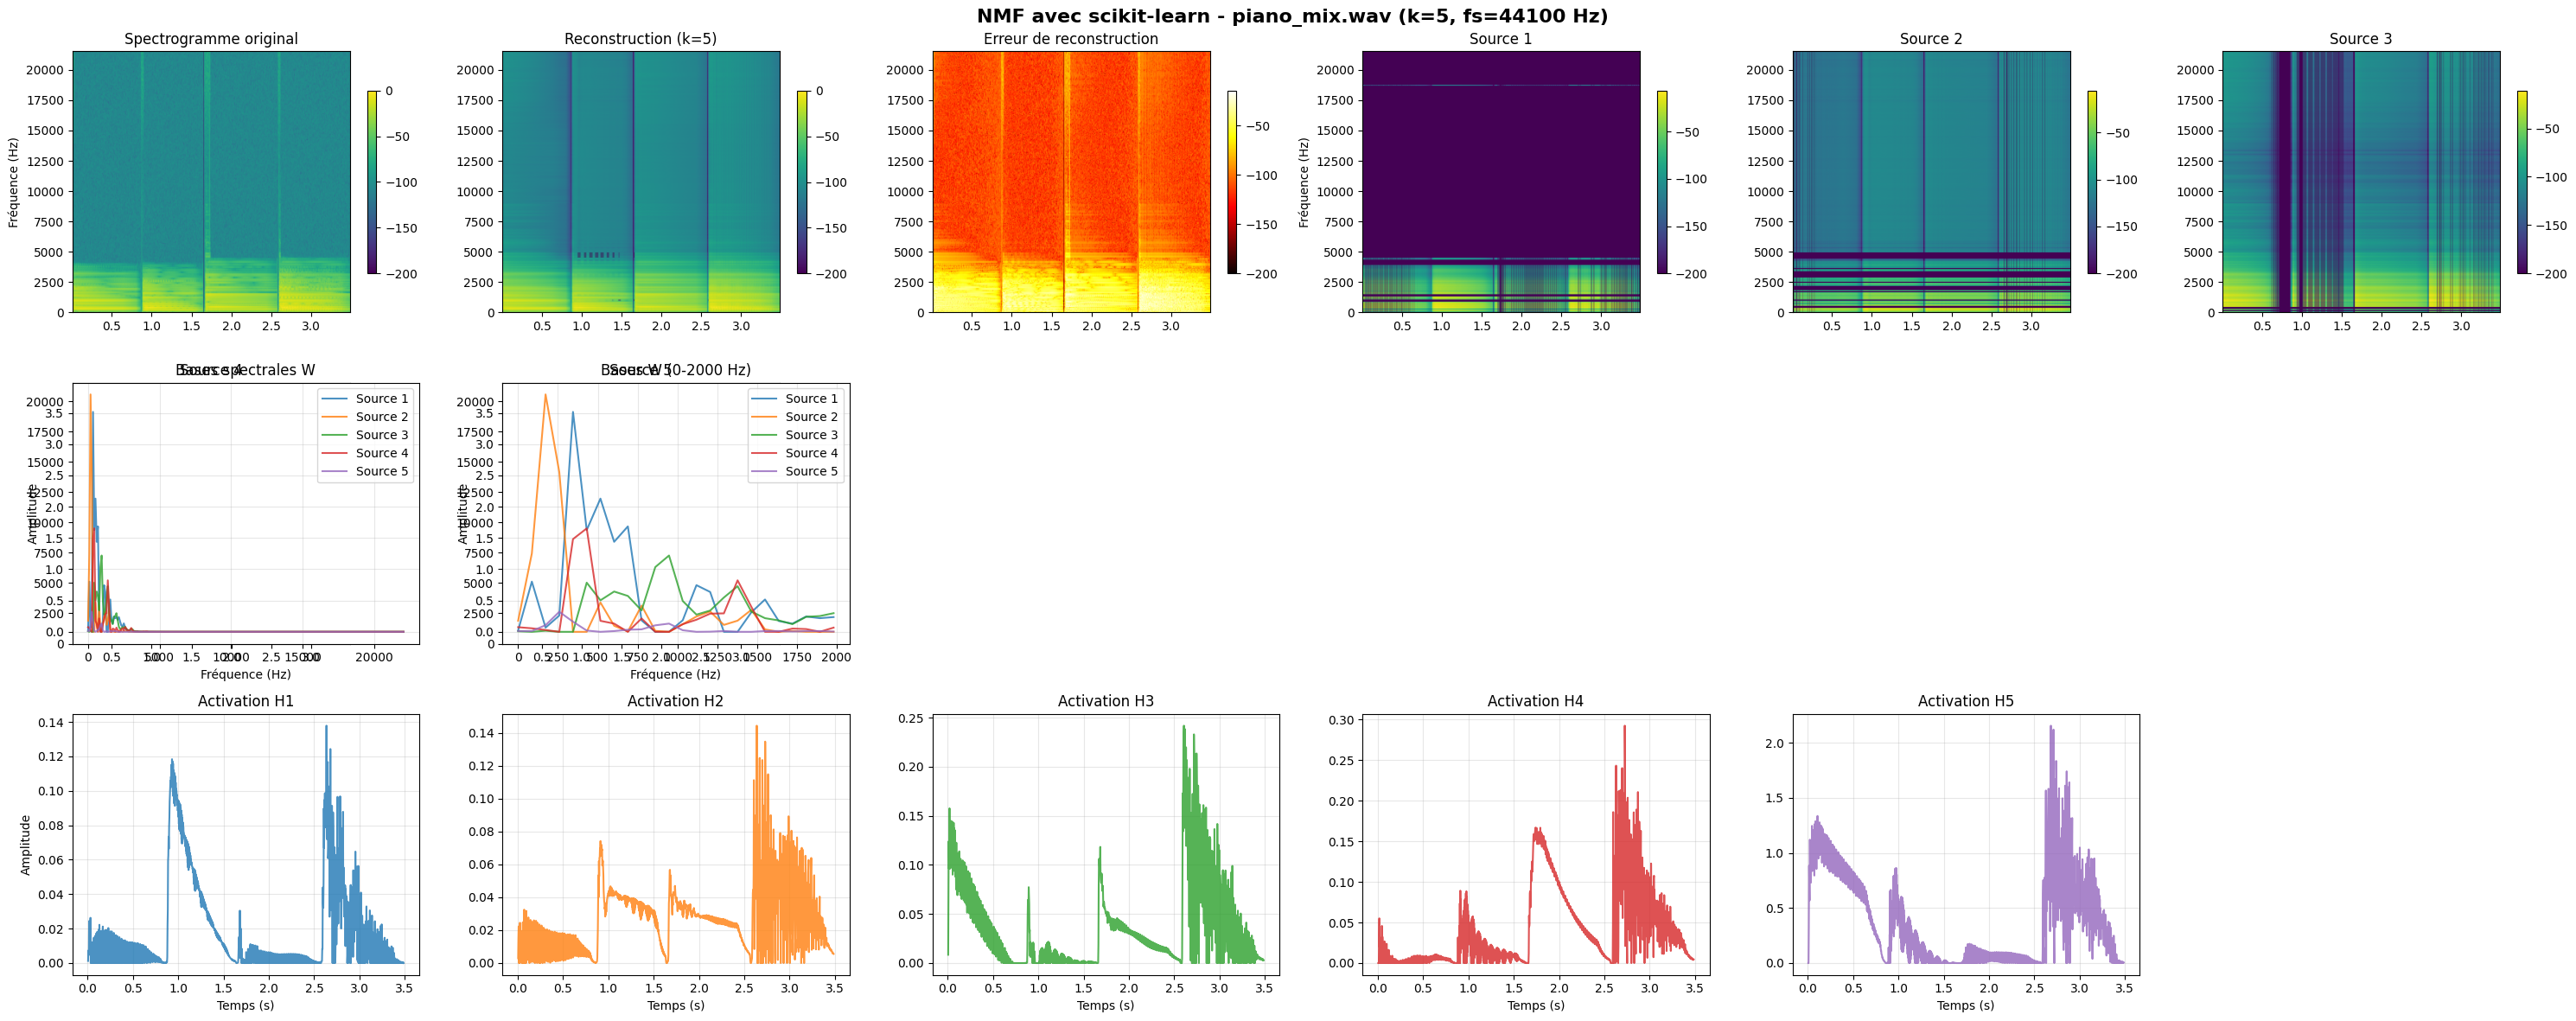


ANALYSE DÉTAILLÉE DES SOURCES

--- Source 1 ---
Fréquences dominantes:
   602.9 Hz: amplitude = 1.439071
   430.7 Hz: amplitude = 1.626849
   689.1 Hz: amplitude = 1.685273
   516.8 Hz: amplitude = 2.129705
   344.5 Hz: amplitude = 3.516348
Activation temporelle:
  Moyenne: 0.017866
  Écart-type: 0.026782
  Min/Max: 0.000000/0.137863
  Entropie spectrale: 2.693 (tonale)

--- Source 2 ---
Fréquences dominantes:
   775.2 Hz: amplitude = 0.418815
   516.8 Hz: amplitude = 0.469152
    86.1 Hz: amplitude = 1.252986
   258.4 Hz: amplitude = 2.553090
   172.3 Hz: amplitude = 3.795676
Activation temporelle:
  Moyenne: 0.026191
  Écart-type: 0.019794
  Min/Max: 0.000000/0.144440
  Entropie spectrale: 1.967 (tonale)

--- Source 3 ---
Fréquences dominantes:
   602.9 Hz: amplitude = 0.644203
  1378.1 Hz: amplitude = 0.729252
   430.7 Hz: amplitude = 0.785772
   861.3 Hz: amplitude = 1.035070
   947.5 Hz: amplitude = 1.219940
Activation temporelle:
  Moyenne: 0.034958
  Écart-type: 0.043895
  Min/

In [131]:
# DEBUG ----------------------------------------------------
#%pip install scikit-learn
from sklearn.decomposition import NMF as SklearnNMF
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. PRÉPARATION DES DONNÉES
# -------------------------------------------------
print("=" * 70)
print("NMF AVEC SCIKIT-LEARN")
print("=" * 70)

# Utiliser la magnitude de notre STFT
V = M_mag_our.copy()  # shape: (n_freqs × n_times)

print(f"Matrice V (spectrogramme):")
print(f"  Shape: {V.shape}")
print(f"  Taille: {V.shape[0]} freq × {V.shape[1]} time")
print(f"  Valeurs: min={V.min():.6f}, max={V.max():.6f}, mean={V.mean():.6f}")

# Normaliser V pour une meilleure convergence
V_normalized = V / V.max()
print(f"  Normalisé: max={V_normalized.max():.1f}")

# -------------------------------------------------
# 2. APPLICATION DE NMF
# -------------------------------------------------
# Choisir le nombre de composantes
# Pour de la musique, on peut essayer différentes valeurs
k_values = [2, 3, 4, 5]

results = {}

for k in k_values:
    print(f"\n{'='*50}")
    print(f"NMF avec k={k} composantes")
    print(f"{'='*50}")
    
    try:
        # Initialiser et entraîner NMF
        model = SklearnNMF(
            n_components=k,
            init='random',  # ou 'nndsvd' pour une meilleure initialisation
            max_iter=200,
            tol=1e-4,
            random_state=42
        )
        
        print("Entraînement en cours...")
        W = model.fit_transform(V_normalized)  # shape: (n_freqs × k)
        H = model.components_                 # shape: (k × n_times)
        
        # Reconstruction
        V_reconstructed = W @ H
        
        # Métriques
        reconstruction_error = model.reconstruction_err_
        
        print(f"✓ Entraînement terminé")
        print(f"  W shape: {W.shape}")
        print(f"  H shape: {H.shape}")
        print(f"  Reconstruction error: {reconstruction_error:.6f}")
        print(f"  Itérations: {model.n_iter_}")
        
        # Stocker les résultats
        results[k] = {
            'W': W,
            'H': H,
            'model': model,
            'V_reconstructed': V_reconstructed,
            'error': reconstruction_error
        }
        
    except Exception as e:
        print(f"✗ Erreur avec k={k}: {e}")

# -------------------------------------------------
# 3. ANALYSE DES RÉSULTATS
# -------------------------------------------------
print(f"\n{'='*70}")
print("ANALYSE DES RÉSULTATS")
print(f"{'='*70}")

if results:
    # Afficher les erreurs par k
    print("\nErreur de reconstruction par nombre de composantes:")
    for k, data in results.items():
        print(f"  k={k}: erreur = {data['error']:.6f}")
    
    # Choisir le meilleur k (plus petite erreur)
    best_k = min(results.keys(), key=lambda k: results[k]['error'])
    print(f"\nMeilleur k: {best_k} (erreur: {results[best_k]['error']:.6f})")
    
    # Utiliser les résultats du meilleur k
    W_best = results[best_k]['W']
    H_best = results[best_k]['H']
    V_recon_best = results[best_k]['V_reconstructed']
    
    # -------------------------------------------------
    # 4. SÉPARATION DES SOURCES
    # -------------------------------------------------
    print(f"\n{'='*70}")
    print(f"SÉPARATION DES SOURCES (k={best_k})")
    print(f"{'='*70}")
    
    # Créer les sources séparées
    sources = []
    for i in range(best_k):
        # Source i = colonne i de W × ligne i de H
        source_i = W_best[:, i:i+1] @ H_best[i:i+1, :]
        sources.append(source_i)
        print(f"Source {i+1}: shape={source_i.shape}, "
              f"min={source_i.min():.6f}, max={source_i.max():.6f}")
    
    # -------------------------------------------------
    # 5. VISUALISATION DES RÉSULTATS
    # -------------------------------------------------
    n_rows = 3
    n_cols = best_k + 1
    
    fig = plt.figure(figsize=(5*n_cols, 4*n_rows))
    
    # Ligne 1: Spectrogrammes originaux et reconstruits
    # Spectrogramme original
    ax1 = plt.subplot(n_rows, n_cols, 1)
    im1 = ax1.imshow(20 * np.log10(V_normalized[:250] + 1e-10), 
                    aspect='auto', origin='lower',
                    extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                    cmap='viridis')
    ax1.set_title('Spectrogramme original')
    ax1.set_ylabel('Fréquence (Hz)')
    plt.colorbar(im1, ax=ax1, shrink=0.7)
    
    # Spectrogramme reconstruit
    ax2 = plt.subplot(n_rows, n_cols, 2)
    im2 = ax2.imshow(20 * np.log10(V_recon_best[:250] + 1e-10), 
                    aspect='auto', origin='lower',
                    extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                    cmap='viridis')
    ax2.set_title(f'Reconstruction (k={best_k})')
    plt.colorbar(im2, ax=ax2, shrink=0.7)
    
    # Erreur de reconstruction
    ax3 = plt.subplot(n_rows, n_cols, 3)
    error = np.abs(V_normalized - V_recon_best)
    im3 = ax3.imshow(20 * np.log10(error[:250] + 1e-10), 
                    aspect='auto', origin='lower',
                    extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                    cmap='hot')
    ax3.set_title('Erreur de reconstruction')
    plt.colorbar(im3, ax=ax3, shrink=0.7)
    
    # Sources séparées
    for i in range(best_k):
        ax = plt.subplot(n_rows, n_cols, i + 4)
        im = ax.imshow(20 * np.log10(sources[i][:250] + 1e-10), 
                      aspect='auto', origin='lower',
                      extent=[times_our[0], times_our[-1], freqs_our[0], freqs_our[250]],
                      cmap='viridis')
        ax.set_title(f'Source {i+1}')
        if i == 0:
            ax.set_ylabel('Fréquence (Hz)')
        plt.colorbar(im, ax=ax, shrink=0.7)
    
    # Ligne 2: Bases spectrales W
    ax_w = plt.subplot(n_rows, n_cols, n_cols + 1)
    for i in range(best_k):
        ax_w.plot(freqs_our, W_best[:, i], label=f'Source {i+1}', alpha=0.8)
    ax_w.set_title('Bases spectrales W')
    ax_w.set_xlabel('Fréquence (Hz)')
    ax_w.set_ylabel('Amplitude')
    ax_w.legend()
    ax_w.grid(True, alpha=0.3)
    
    # Zoom sur les basses fréquences (0-2000 Hz)
    ax_w_zoom = plt.subplot(n_rows, n_cols, n_cols + 2)
    freq_limit = 2000
    freq_mask = freqs_our <= freq_limit
    for i in range(best_k):
        ax_w_zoom.plot(freqs_our[freq_mask], W_best[freq_mask, i], 
                      label=f'Source {i+1}', alpha=0.8)
    ax_w_zoom.set_title(f'Bases W (0-{freq_limit} Hz)')
    ax_w_zoom.set_xlabel('Fréquence (Hz)')
    ax_w_zoom.set_ylabel('Amplitude')
    ax_w_zoom.legend()
    ax_w_zoom.grid(True, alpha=0.3)
    
    # Ligne 3: Activations temporelles H
    for i in range(best_k):
        ax_h = plt.subplot(n_rows, n_cols, 2*n_cols + i + 1)
        ax_h.plot(times_our, H_best[i, :], color=f'C{i}', alpha=0.8)
        ax_h.set_title(f'Activation H{i+1}')
        ax_h.set_xlabel('Temps (s)')
        if i == 0:
            ax_h.set_ylabel('Amplitude')
        ax_h.grid(True, alpha=0.3)
    
    plt.suptitle(f'NMF avec scikit-learn - piano_mix.wav (k={best_k}, fs={fs} Hz)', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # -------------------------------------------------
    # 6. ANALYSE DES SOURCES
    # -------------------------------------------------
    print(f"\n{'='*70}")
    print("ANALYSE DÉTAILLÉE DES SOURCES")
    print(f"{'='*70}")
    
    for i in range(best_k):
        print(f"\n--- Source {i+1} ---")
        
        # Fréquences dominantes
        source_spectrum = W_best[:, i]
        top_freq_indices = np.argsort(source_spectrum)[-5:]  # 5 plus grandes valeurs
        top_freqs = freqs_our[top_freq_indices]
        top_amps = source_spectrum[top_freq_indices]
        
        print(f"Fréquences dominantes:")
        for freq, amp in zip(top_freqs, top_amps):
            print(f"  {freq:6.1f} Hz: amplitude = {amp:.6f}")
        
        # Analyse temporelle
        activation = H_best[i, :]
        print(f"Activation temporelle:")
        print(f"  Moyenne: {activation.mean():.6f}")
        print(f"  Écart-type: {activation.std():.6f}")
        print(f"  Min/Max: {activation.min():.6f}/{activation.max():.6f}")
        
        # Identifier si la source est plutôt tonale (pic étroit) ou bruit (large)
        spectrum_normalized = source_spectrum / source_spectrum.sum()
        entropy = -np.sum(spectrum_normalized * np.log(spectrum_normalized + 1e-10))
        print(f"  Entropie spectrale: {entropy:.3f} "
              f"({'tonale' if entropy < 3 else 'bruit'})")
    
    # -------------------------------------------------
    # 7. RECONSTRUCTION AUDIO (OPTIONNEL)
    # -------------------------------------------------
    print(f"\n{'='*70}")
    print("INFORMATION POUR LA RECONSTRUCTION AUDIO")
    print(f"{'='*70}")
    
    print(f"\nPour reconstruire le signal audio à partir des sources:")
    print(f"1. Prendre la phase du STFT original: phase = np.angle(M_our)")
    print(f"2. Pour chaque source i:")
    print(f"   - Créer STFT complexe: source_complex_i = sources[i] * np.exp(1j * phase)")
    print(f"   - Appliquer ISTFT (à implémenter)")
    print(f"3. Sauvegarder les signaux séparés en fichiers .wav")
    
    print(f"\nMatrices disponibles:")
    print(f"  Phase originale: shape {M_our.shape}")
    print(f"  Sources séparées: {len(sources)} sources de shape {sources[0].shape}")
    
else:
    print("Aucun résultat NMF disponible!")

print(f"\n{'='*70}")
print("FIN DE L'ANALYSE NMF")
print(f"{'='*70}")

NMF AVEC SCIKIT-LEARN + RECONSTRUCTION AUDIO
Matrice V (spectrogramme):
  Shape: (257, 1200)
  Taille: 257 freq × 1200 time
  Valeurs: min=0.000000, max=64.635739, mean=0.392537
  Normalisé: max=1.0
  Phase originale: shape=(257, 1200)

NMF avec k=3 composantes
Entraînement NMF en cours...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


✓ NMF terminé
  W shape: (257, 3)
  H shape: (3, 1200)
  Reconstruction error: 4.545698
  Itérations: 300

SÉPARATION DES SOURCES
Source 1: shape=(257, 1200), min=0.000000, max=0.761436
Source 2: shape=(257, 1200), min=0.000000, max=0.542588
Source 3: shape=(257, 1200), min=0.000000, max=0.561753
Source 1 complexe: shape=(257, 1200)
Source 2 complexe: shape=(257, 1200)
Source 3 complexe: shape=(257, 1200)

RECONSTRUCTION AUDIO (ISTFT)
Paramètres ISTFT:
  nperseg: 512
  hop: 128
  noverlap: 384
  window: hann
  fs: 44100

Reconstruction du signal original...
✓ Signal original reconstruit: 153472 échantillons

Reconstruction des sources séparées...
  Source 1...
    ✓ 153472 échantillons reconstruits
    Durée: 3.48 secondes
  Source 2...
    ✓ 153472 échantillons reconstruits
    Durée: 3.48 secondes
  Source 3...
    ✓ 153472 échantillons reconstruits
    Durée: 3.48 secondes

✓ Mélange reconstruit à partir des sources: 153472 échantillons

SAUVEGARDE DES FICHIERS AUDIO
✓ Original reco

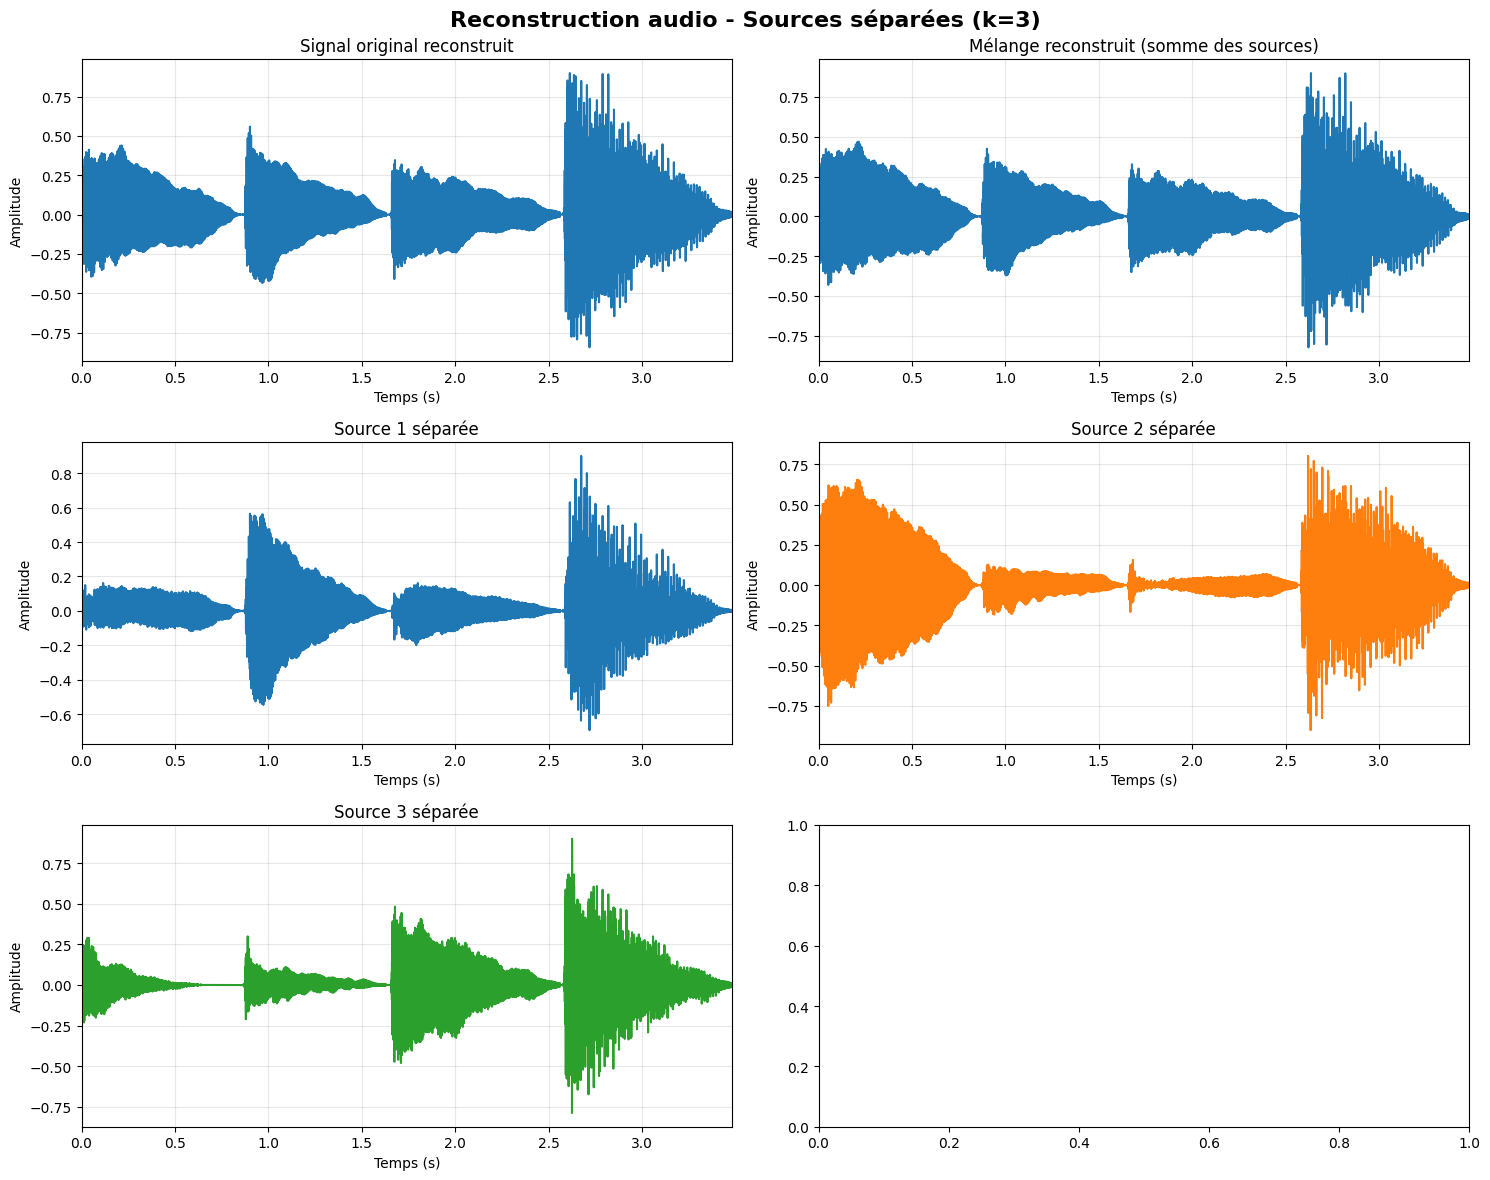


ANALYSE SPECTRALE DES SIGNAUX RECONSTRUITS


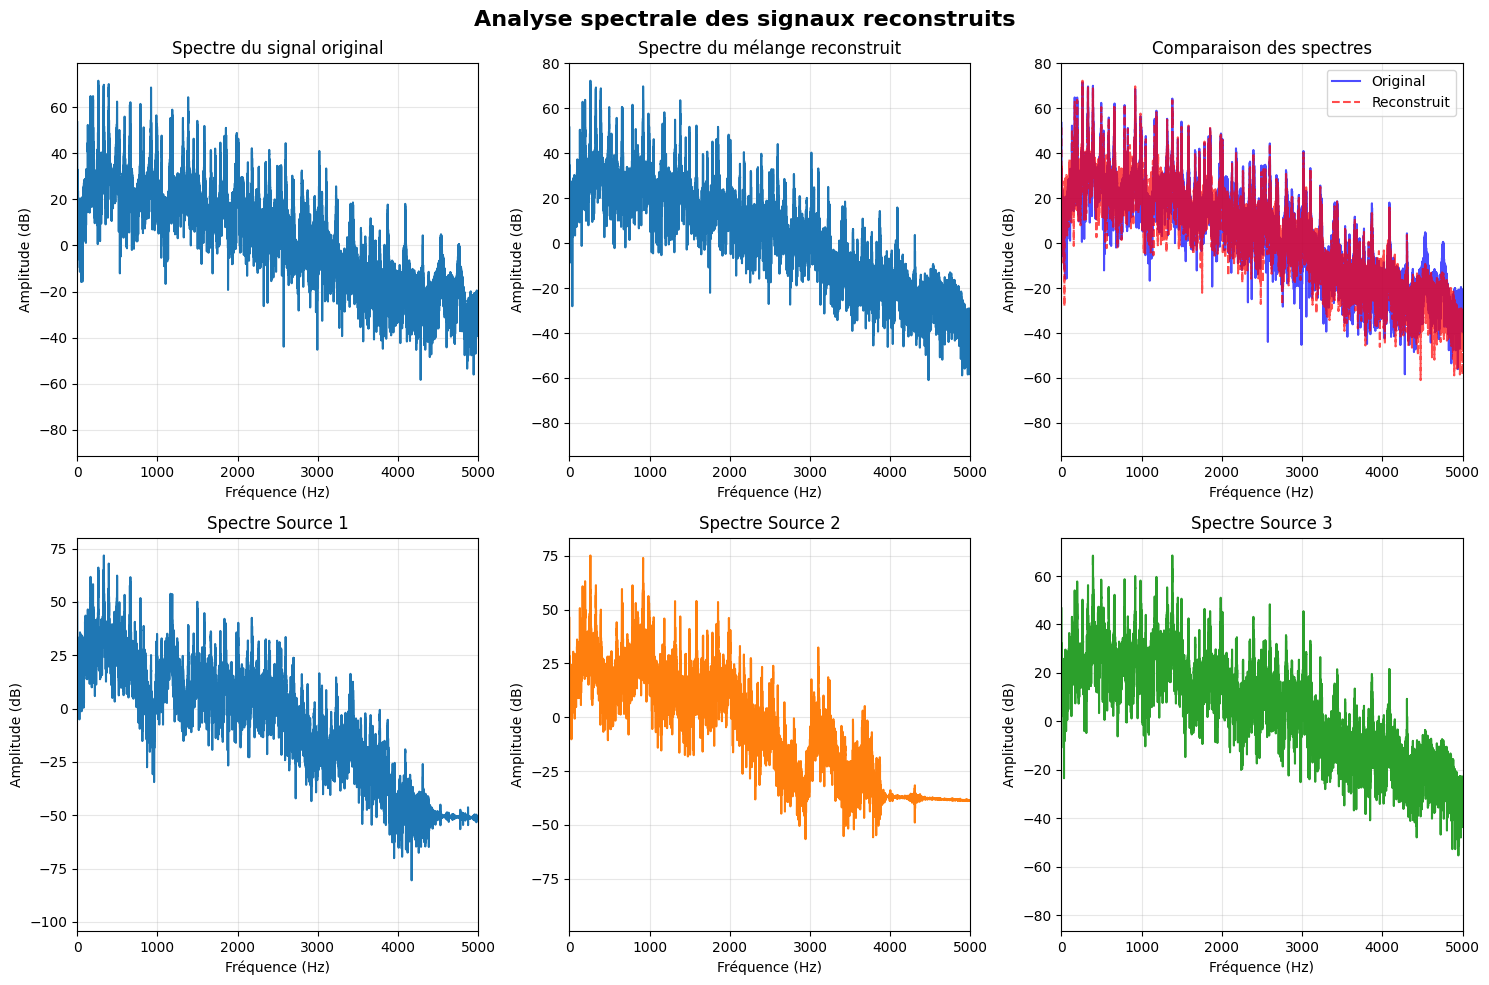


RÉSUMÉ DE LA SÉPARATION DE SOURCES

Fichiers sauvegardés dans le dossier: separated_sources/
Tu peux maintenant écouter les résultats!

Recommandations pour améliorer la séparation:
1. Essayer différentes valeurs de k (2, 4, 5)
2. Utiliser beta_loss='kullback-leibler' pour NMF (meilleur pour audio)
3. Prétraiter le spectrogramme (log compression, etc.)
4. Implémenter notre propre NMF avec régularisation

Prochaines étapes pour le projet:
1. Tester sur d'autres fichiers audio du dataset
2. Implémenter l'ISTFT pour compléter notre pipeline maison
3. Évaluer objectivement la qualité de séparation
4. Optimiser les paramètres pour chaque type de musique

FIN DU PIPELINE COMPLET STFT + NMF + ISTFT


In [132]:
#%pip install soundfile
from sklearn.decomposition import NMF as SklearnNMF
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import istft as scipy_istft
import scipy.io.wavfile
import soundfile as sf  # Alternative pour sauvegarder

# -------------------------------------------------
# 1. PRÉPARATION DES DONNÉES
# -------------------------------------------------
print("=" * 70)
print("NMF AVEC SCIKIT-LEARN + RECONSTRUCTION AUDIO")
print("=" * 70)

# Utiliser la magnitude de notre STFT
V = M_mag_our.copy()  # shape: (n_freqs × n_times)

print(f"Matrice V (spectrogramme):")
print(f"  Shape: {V.shape}")
print(f"  Taille: {V.shape[0]} freq × {V.shape[1]} time")
print(f"  Valeurs: min={V.min():.6f}, max={V.max():.6f}, mean={V.mean():.6f}")

# Normaliser V pour une meilleure convergence
V_normalized = V / V.max()
print(f"  Normalisé: max={V_normalized.max():.1f}")

# Garder la phase originale pour reconstruction
phase_original = np.angle(M_our)  # shape: (n_freqs × n_times)
print(f"  Phase originale: shape={phase_original.shape}")

# -------------------------------------------------
# 2. APPLICATION DE NMF
# -------------------------------------------------
# Choisir le nombre de composantes
k = 3  # Pour un piano, 3 composantes est un bon point de départ

print(f"\n{'='*50}")
print(f"NMF avec k={k} composantes")
print(f"{'='*50}")

try:
    # Initialiser et entraîner NMF
    model = SklearnNMF(
        n_components=k,
        init='nndsvd',  # Meilleure initialisation que 'random'
        max_iter=300,
        tol=1e-4,
        random_state=42,
        beta_loss='frobenius'  # Loss standard pour NMF
    )
    
    print("Entraînement NMF en cours...")
    W = model.fit_transform(V_normalized)  # shape: (n_freqs × k)
    H = model.components_                 # shape: (k × n_times)
    
    # Reconstruction
    V_reconstructed = W @ H
    
    print(f"✓ NMF terminé")
    print(f"  W shape: {W.shape}")
    print(f"  H shape: {H.shape}")
    print(f"  Reconstruction error: {model.reconstruction_err_:.6f}")
    print(f"  Itérations: {model.n_iter_}")
    
except Exception as e:
    print(f"✗ Erreur NMF: {e}")
    raise

# -------------------------------------------------
# 3. SÉPARATION DES SOURCES
# -------------------------------------------------
print(f"\n{'='*50}")
print(f"SÉPARATION DES SOURCES")
print(f"{'='*50}")

# Créer les sources séparées (spectrogrammes magnitude)
sources_magnitude = []
for i in range(k):
    # Source i = colonne i de W × ligne i de H
    source_i_mag = W[:, i:i+1] @ H[i:i+1, :]
    sources_magnitude.append(source_i_mag)
    print(f"Source {i+1}: shape={source_i_mag.shape}, "
          f"min={source_i_mag.min():.6f}, max={source_i_mag.max():.6f}")

# Créer les STFT complexes pour chaque source
sources_complex = []
for i in range(k):
    # Recombiner magnitude estimée avec phase originale
    source_complex = sources_magnitude[i] * np.exp(1j * phase_original)
    sources_complex.append(source_complex)
    print(f"Source {i+1} complexe: shape={source_complex.shape}")

# -------------------------------------------------
# 4. RECONSTRUCTION AUDIO AVEC ISTFT
# -------------------------------------------------
print(f"\n{'='*50}")
print(f"RECONSTRUCTION AUDIO (ISTFT)")
print(f"{'='*50}")

# Paramètres pour l'ISTFT (doivent correspondre à la STFT)
nperseg = meta_our['nperseg']
hop = meta_our['hop']
noverlap = nperseg - hop
window = meta_our['window']

print(f"Paramètres ISTFT:")
print(f"  nperseg: {nperseg}")
print(f"  hop: {hop}")
print(f"  noverlap: {noverlap}")
print(f"  window: {window}")
print(f"  fs: {fs}")

# Fonction pour reconstruire un signal avec ISTFT SciPy
def reconstruct_audio_from_stft(stft_complex, fs, nperseg, noverlap, window='hann'):
    """
    Reconstruit un signal audio à partir d'un STFT complexe.
    
    Note: SciPy's ISTFT attend (freqs × time) comme entrée, ce que nous avons déjà.
    """
    # Transposer pour avoir (time × freqs) si nécessaire
    # Mais scipy.stft retourne (freqs × time), donc on garde comme ça
    
    # Calculer l'ISTFT
    try:
        t, signal_reconstructed = scipy_istft(
            stft_complex,
            fs=fs,
            window=window,
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nperseg,
            input_onesided=True,
            boundary=True
        )
        
        # Normaliser pour éviter le clipping
        signal_reconstructed = signal_reconstructed / np.max(np.abs(signal_reconstructed)) * 0.9
        
        return t, signal_reconstructed
        
    except Exception as e:
        print(f"Erreur ISTFT: {e}")
        # Essayer avec des paramètres simplifiés
        t, signal_reconstructed = scipy_istft(
            stft_complex,
            fs=fs
        )
        signal_reconstructed = signal_reconstructed / np.max(np.abs(signal_reconstructed)) * 0.9
        return t, signal_reconstructed

# Reconstruire le signal original (pour vérification)
print("\nReconstruction du signal original...")
try:
    # Pour le signal original, utiliser le STFT complexe original
    t_orig, signal_orig_reconstructed = reconstruct_audio_from_stft(
        M_our, fs, nperseg, noverlap, window
    )
    print(f"✓ Signal original reconstruit: {len(signal_orig_reconstructed)} échantillons")
except Exception as e:
    print(f"✗ Erreur reconstruction originale: {e}")
    signal_orig_reconstructed = None

# Reconstruire chaque source séparée
separated_signals = []
separated_times = []

print(f"\nReconstruction des sources séparées...")
for i in range(k):
    print(f"  Source {i+1}...")
    try:
        t_i, signal_i = reconstruct_audio_from_stft(
            sources_complex[i], fs, nperseg, noverlap, window
        )
        separated_signals.append(signal_i)
        separated_times.append(t_i)
        print(f"    ✓ {len(signal_i)} échantillons reconstruits")
        print(f"    Durée: {len(signal_i)/fs:.2f} secondes")
        
    except Exception as e:
        print(f"    ✗ Erreur: {e}")
        separated_signals.append(None)
        separated_times.append(None)

# Reconstruire le mélange à partir des sources séparées (pour vérification)
if all(s is not None for s in separated_signals):
    # Assurer que tous les signaux ont la même longueur
    min_length = min(len(s) for s in separated_signals)
    separated_signals_truncated = [s[:min_length] for s in separated_signals]
    
    # Reconstruire le mélange
    mixture_reconstructed = np.sum(separated_signals_truncated, axis=0)
    mixture_reconstructed = mixture_reconstructed / np.max(np.abs(mixture_reconstructed)) * 0.9
    
    print(f"\n✓ Mélange reconstruit à partir des sources: {len(mixture_reconstructed)} échantillons")
else:
    mixture_reconstructed = None
    print(f"\n✗ Impossible de reconstruire le mélange")

# -------------------------------------------------
# 5. SAUVEGARDE DES FICHIERS AUDIO
# -------------------------------------------------
print(f"\n{'='*50}")
print(f"SAUVEGARDE DES FICHIERS AUDIO")
print(f"{'='*50}")

output_dir = "separated_sources"
import os
os.makedirs(output_dir, exist_ok=True)

# Sauvegarder le signal original reconstruit
if signal_orig_reconstructed is not None:
    original_path = os.path.join(output_dir, "original_reconstructed.wav")
    scipy.io.wavfile.write(original_path, fs, 
                          (signal_orig_reconstructed * 32767).astype(np.int16))
    print(f"✓ Original reconstruit sauvegardé: {original_path}")

# Sauvegarder chaque source séparée
for i in range(k):
    if separated_signals[i] is not None:
        source_path = os.path.join(output_dir, f"source_{i+1}.wav")
        # Convertir en int16 pour WAV
        signal_int16 = (separated_signals[i] * 32767).astype(np.int16)
        scipy.io.wavfile.write(source_path, fs, signal_int16)
        print(f"✓ Source {i+1} sauvegardée: {source_path}")

# Sauvegarder le mélange reconstruit
if mixture_reconstructed is not None:
    mixture_path = os.path.join(output_dir, "mixture_reconstructed.wav")
    mixture_int16 = (mixture_reconstructed * 32767).astype(np.int16)
    scipy.io.wavfile.write(mixture_path, fs, mixture_int16)
    print(f"✓ Mélange reconstruit sauvegardé: {mixture_path}")

# -------------------------------------------------
# 6. VISUALISATION DES RÉSULTATS AUDIO
# -------------------------------------------------
print(f"\n{'='*50}")
print(f"VISUALISATION DES SIGNAUX AUDIO")
print(f"{'='*50}")

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Signal original (si disponible)
if signal_orig_reconstructed is not None:
    ax = axes[0, 0]
    time_axis = np.arange(len(signal_orig_reconstructed)) / fs
    ax.plot(time_axis, signal_orig_reconstructed)
    ax.set_title('Signal original reconstruit')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, min(10, time_axis[-1])])  # Limiter à 10 secondes

# Mélange reconstruit (si disponible)
if mixture_reconstructed is not None:
    ax = axes[0, 1]
    time_axis = np.arange(len(mixture_reconstructed)) / fs
    ax.plot(time_axis, mixture_reconstructed)
    ax.set_title('Mélange reconstruit (somme des sources)')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, min(10, time_axis[-1])])

# Sources séparées (premières 3)
for i in range(min(k, 3)):
    if separated_signals[i] is not None:
        ax = axes[1 + i//2, i%2]
        time_axis = np.arange(len(separated_signals[i])) / fs
        ax.plot(time_axis, separated_signals[i], color=f'C{i}')
        ax.set_title(f'Source {i+1} séparée')
        ax.set_xlabel('Temps (s)')
        ax.set_ylabel('Amplitude')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, min(10, time_axis[-1])])

plt.suptitle(f'Reconstruction audio - Sources séparées (k={k})', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------
# 7. ANALYSE SPECTRALE DES SIGNAUX RECONSTRUITS
# -------------------------------------------------
print(f"\n{'='*50}")
print(f"ANALYSE SPECTRALE DES SIGNAUX RECONSTRUITS")
print(f"{'='*50}")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Spectre du signal original
if signal_orig_reconstructed is not None:
    ax = axes[0, 0]
    spectrum_orig = np.abs(np.fft.rfft(signal_orig_reconstructed))
    freq_axis = np.fft.rfftfreq(len(signal_orig_reconstructed), 1/fs)
    ax.plot(freq_axis, 20*np.log10(spectrum_orig + 1e-10))
    ax.set_title('Spectre du signal original')
    ax.set_xlabel('Fréquence (Hz)')
    ax.set_ylabel('Amplitude (dB)')
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 5000])  # Limiter à 5 kHz

# Spectre du mélange reconstruit
if mixture_reconstructed is not None:
    ax = axes[0, 1]
    spectrum_mix = np.abs(np.fft.rfft(mixture_reconstructed))
    freq_axis = np.fft.rfftfreq(len(mixture_reconstructed), 1/fs)
    ax.plot(freq_axis, 20*np.log10(spectrum_mix + 1e-10))
    ax.set_title('Spectre du mélange reconstruit')
    ax.set_xlabel('Fréquence (Hz)')
    ax.set_ylabel('Amplitude (dB)')
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 5000])

# Spectres comparés
if signal_orig_reconstructed is not None and mixture_reconstructed is not None:
    ax = axes[0, 2]
    min_len = min(len(signal_orig_reconstructed), len(mixture_reconstructed))
    spectrum_orig = np.abs(np.fft.rfft(signal_orig_reconstructed[:min_len]))
    spectrum_mix = np.abs(np.fft.rfft(mixture_reconstructed[:min_len]))
    freq_axis = np.fft.rfftfreq(min_len, 1/fs)
    ax.plot(freq_axis, 20*np.log10(spectrum_orig + 1e-10), 'b-', label='Original', alpha=0.7)
    ax.plot(freq_axis, 20*np.log10(spectrum_mix + 1e-10), 'r--', label='Reconstruit', alpha=0.7)
    ax.set_title('Comparaison des spectres')
    ax.set_xlabel('Fréquence (Hz)')
    ax.set_ylabel('Amplitude (dB)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 5000])

# Spectres des sources séparées
for i in range(min(k, 3)):
    if separated_signals[i] is not None:
        ax = axes[1, i]
        spectrum_source = np.abs(np.fft.rfft(separated_signals[i]))
        freq_axis = np.fft.rfftfreq(len(separated_signals[i]), 1/fs)
        ax.plot(freq_axis, 20*np.log10(spectrum_source + 1e-10), color=f'C{i}')
        ax.set_title(f'Spectre Source {i+1}')
        ax.set_xlabel('Fréquence (Hz)')
        ax.set_ylabel('Amplitude (dB)')
        ax.grid(True, alpha=0.3)
        ax.set_xlim([0, 5000])

plt.suptitle(f'Analyse spectrale des signaux reconstruits', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------
# 8. RÉSUMÉ ET CONCLUSION
# -------------------------------------------------
print(f"\n{'='*70}")
print("RÉSUMÉ DE LA SÉPARATION DE SOURCES")
print(f"{'='*70}")

print(f"\nFichiers sauvegardés dans le dossier: {output_dir}/")
print("Tu peux maintenant écouter les résultats!")

print(f"\nRecommandations pour améliorer la séparation:")
print(f"1. Essayer différentes valeurs de k (2, 4, 5)")
print(f"2. Utiliser beta_loss='kullback-leibler' pour NMF (meilleur pour audio)")
print(f"3. Prétraiter le spectrogramme (log compression, etc.)")
print(f"4. Implémenter notre propre NMF avec régularisation")

print(f"\nProchaines étapes pour le projet:")
print(f"1. Tester sur d'autres fichiers audio du dataset")
print(f"2. Implémenter l'ISTFT pour compléter notre pipeline maison")
print(f"3. Évaluer objectivement la qualité de séparation")
print(f"4. Optimiser les paramètres pour chaque type de musique")

print(f"\n{'='*70}")
print("FIN DU PIPELINE COMPLET STFT + NMF + ISTFT")
print(f"{'='*70}")

In [133]:
# -------------------------------------------------
# NMF DIRECTEMENT SUR SCIPY STFT
# -------------------------------------------------
print("=" * 70)
print("NMF DIRECT SUR STFT SCIPY (sans notre normalisation)")
print("=" * 70)

# Utiliser la STFT de SciPy SANS notre normalisation
# D'abord, recalculer notre STFT sans scipy_scale
M_our_no_scale, freqs_our, times_our, meta_our = stft(
    x, fs, nperseg, 
    window='hann',
    hop_fraction=hop_fraction,
    output="magnitude",
    scipy_scale=False  # IMPORTANT: Pas de division par nperseg/2
)

M_scipy_mag = np.abs(M_sp)  # Magnitude de SciPy

print(f"Notre STFT (sans scale): shape={M_our_no_scale.shape}, max={M_our_no_scale.max():.4f}")
print(f"SciPy STFT: shape={M_scipy_mag.shape}, max={M_scipy_mag.max():.4f}")

# Comparer les échelles
print(f"\nComparaison d'échelle:")
print(f"  Notre (sans scale) / SciPy = {M_our_no_scale.max() / M_scipy_mag.max():.4f}")
print(f"  Facteur attendu: nperseg/2 = {nperseg/2} = {nperseg/2}")

# -------------------------------------------------
# TEST NMF SUR LES 3 MATRICES
# -------------------------------------------------
print(f"\n{'='*70}")
print("TEST NMF SUR DIFFÉRENTES MATRICES")
print("=" * 70)

test_matrices = {
    "Notre STFT (avec scale)": M_mag_our,
    "Notre STFT (sans scale)": M_our_no_scale,
    "SciPy STFT": M_scipy_mag
}

for name, matrix in test_matrices.items():
    print(f"\n{'='*50}")
    print(f"TEST: {name}")
    print(f"{'='*50}")
    
    # Normaliser pour NMF
    V = matrix.copy()
    V_normalized = V / V.max()
    
    print(f"  Matrice: shape={V.shape}")
    print(f"  Valeurs originales: min={V.min():.6f}, max={V.max():.6f}, mean={V.mean():.6f}")
    print(f"  Valeurs normalisées: min={V_normalized.min():.6f}, max={V_normalized.max():.6f}")
    
    # Tester avec scikit-learn NMF
    k = 3
    try:
        model = SklearnNMF(
            n_components=k,
            init='nndsvd',
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
        
        W = model.fit_transform(V_normalized)
        H = model.components_
        reconstruction_error = model.reconstruction_err_
        
        print(f"  ✓ NMF réussi")
        print(f"    Reconstruction error: {reconstruction_error:.6f}")
        print(f"    Itérations: {model.n_iter_}")
        
        # Analyser la séparation
        # Calculer la "propreté" de la séparation
        W_normalized = W / (W.sum(axis=0) + 1e-10)  # Normaliser les colonnes
        H_normalized = H / (H.sum(axis=1, keepdims=True) + 1e-10)  # Normaliser les lignes
        
        # Mesure de séparation: combien chaque source est "pure"
        separation_score = 0
        for i in range(k):
            # Pour chaque source, regarder combien elle est concentrée
            w_concentration = np.sum(W_normalized[:, i] > 0.1) / len(W_normalized[:, i])
            h_concentration = np.sum(H_normalized[i, :] > 0.1) / len(H_normalized[i, :])
            separation_score += (1 - w_concentration) * (1 - h_concentration)
        
        separation_score = separation_score / k
        print(f"    Score de séparation: {separation_score:.4f} (1=parfait)")
        
    except Exception as e:
        print(f"  ✗ Erreur NMF: {e}")

# -------------------------------------------------
# CORRECTION DE TON NMF
# -------------------------------------------------
print(f"\n{'='*70}")
print("CORRECTION DE TON NMF_MULTIPLICATIVE")
print("=" * 70)

def NMF_corrected(V, k, max_iter=500, tol=1e-6, random_state=None):
    """
    Version corrigée de NMF multiplicative.
    
    V: matrice non-négative (freq × time)
    k: nombre de composantes
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    n_freqs, n_times = V.shape
    epsilon = 1e-10
    
    # Initialisation améliorée
    # Utiliser nndsvd-like initialization
    W = np.random.rand(n_freqs, k) * np.sqrt(V.mean())
    H = np.random.rand(k, n_times) * np.sqrt(V.mean())
    
    costs = []
    
    for iteration in range(max_iter):
        # Mise à jour multiplicative
        # H <- H * (W^T V) / (W^T W H)
        numerator_H = W.T @ V
        denominator_H = W.T @ W @ H + epsilon
        H = H * numerator_H / denominator_H
        
        # W <- W * (V H^T) / (W H H^T)
        numerator_W = V @ H.T
        denominator_W = W @ H @ H.T + epsilon
        W = W * numerator_W / denominator_W
        
        # Calcul du coût (erreur de reconstruction)
        V_approx = W @ H
        cost = np.linalg.norm(V - V_approx, 'fro') ** 2
        costs.append(cost)
        
        # Vérifier la convergence
        if iteration > 0 and abs(costs[-2] - costs[-1]) < tol:
            print(f"    Convergence à l'itération {iteration}")
            break
    
    return W, H, costs

# Tester avec différentes matrices
print(f"\nTest de notre NMF corrigé:")

for name, matrix in test_matrices.items():
    print(f"\n  {name}:")
    V_test = matrix / matrix.max()  # Normaliser
    
    try:
        W, H, costs = NMF_corrected(V_test, k=3, max_iter=200, random_state=42)
        final_cost = costs[-1]
        print(f"    ✓ Coût final: {final_cost:.6f}")
        print(f"    Itérations: {len(costs)}")
        
        # Vérifier la non-négativité
        W_min, H_min = W.min(), H.min()
        if W_min < -1e-10 or H_min < -1e-10:
            print(f"    ⚠️ Valeurs négatives: W.min={W_min:.2e}, H.min={H_min:.2e}")
        else:
            print(f"    ✓ Matrices non-négatives")
            
    except Exception as e:
        print(f"    ✗ Erreur: {e}")

# -------------------------------------------------
# RECOMMANDATIONS FINALES
# -------------------------------------------------
print(f"\n{'='*70}")
print("RECOMMANDATIONS")
print("=" * 70)

print(f"\n1. PROBLÈME PRINCIPAL : ÉCHELLE DES DONNÉES")
print(f"   - Avec scipy_scale=True: valeurs très petites (÷{nperseg/2})")
print(f"   - Pour NMF: utiliser scipy_scale=False ou ajuster l'initialisation")

print(f"\n2. POUR TON NMF_MULTIPLICATIVE:")
print(f"   - Ajouter epsilon dans les dénominateurs")
print(f"   - Améliorer l'initialisation (pas trop petite)")
print(f"   - Normaliser les données avant NMF (diviser par max)")

print(f"\n3. POUR MEILLEURE SÉPARATION:")
print(f"   - Essayer log(1 + V) au lieu de V (compression logarithmique)")
print(f"   - Utiliser k=4 ou 5 pour la musique")
print(f"   - Ajouter de la régularisation (sparsité)")

print(f"\n4. CODE CORRIGÉ POUR NMF:")
print(f"""
def NMF_improved(V, k, max_iter=500, tol=1e-6):
    \"\"\"NMF amélioré pour audio.\"\"\"
    n_freqs, n_times = V.shape
    epsilon = 1e-10
    
    # 1. Compression logarithmique (meilleur pour audio)
    V_log = np.log1p(V * 100)  # log(1 + 100*V)
    V_log = V_log / V_log.max()
    
    # 2. Initialisation améliorée
    W = np.random.rand(n_freqs, k) * 0.5 + 0.1
    H = np.random.rand(k, n_times) * 0.5 + 0.1
    
    costs = []
    for i in range(max_iter):
        # Mise à jour H
        numerator_H = W.T @ V_log
        denominator_H = W.T @ W @ H + epsilon
        H = H * numerator_H / denominator_H
        
        # Mise à jour W  
        numerator_W = V_log @ H.T
        denominator_W = W @ H @ H.T + epsilon
        W = W * numerator_W / denominator_W
        
        # Coût
        V_approx = W @ H
        cost = np.linalg.norm(V_log - V_approx, 'fro')**2
        costs.append(cost)
        
        if i > 10 and abs(costs[-2]-costs[-1]) < tol:
            break
    
    # Reconvertir à l'échelle originale
    W = W * V.max()  # Ajuster l'échelle
    return W, H, costs
""")

print(f"\n{'='*70}")
print("EXÉCUTE CES TESTS POUR VOIR LA DIFFÉRENCE")
print(f"{'='*70}")

NMF DIRECT SUR STFT SCIPY (sans notre normalisation)
Notre STFT (sans scale): shape=(257, 1200), max=64.6357
SciPy STFT: shape=(257, 1200), max=0.2529

Comparaison d'échelle:
  Notre (sans scale) / SciPy = 255.5790
  Facteur attendu: nperseg/2 = 256.0 = 256.0

TEST NMF SUR DIFFÉRENTES MATRICES

TEST: Notre STFT (avec scale)
  Matrice: shape=(257, 1200)
  Valeurs originales: min=0.000000, max=64.635739, mean=0.392537
  Valeurs normalisées: min=0.000000, max=1.000000


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(
/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


  ✓ NMF réussi
    Reconstruction error: 4.545698
    Itérations: 300
    Score de séparation: 0.9896 (1=parfait)

TEST: Notre STFT (sans scale)
  Matrice: shape=(257, 1200)
  Valeurs originales: min=0.000000, max=64.635739, mean=0.392537
  Valeurs normalisées: min=0.000000, max=1.000000
  ✓ NMF réussi
    Reconstruction error: 4.545698
    Itérations: 300
    Score de séparation: 0.9896 (1=parfait)

TEST: SciPy STFT
  Matrice: shape=(257, 1200)
  Valeurs originales: min=0.000000, max=0.252899, mean=0.001535
  Valeurs normalisées: min=0.000000, max=1.000000


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


  ✓ NMF réussi
    Reconstruction error: 4.543365
    Itérations: 300
    Score de séparation: 0.9896 (1=parfait)

CORRECTION DE TON NMF_MULTIPLICATIVE

Test de notre NMF corrigé:

  Notre STFT (avec scale):
    ✓ Coût final: 20.754141
    Itérations: 200
    ✓ Matrices non-négatives

  Notre STFT (sans scale):
    ✓ Coût final: 20.754141
    Itérations: 200
    ✓ Matrices non-négatives

  SciPy STFT:
    ✓ Coût final: 20.733401
    Itérations: 200
    ✓ Matrices non-négatives

RECOMMANDATIONS

1. PROBLÈME PRINCIPAL : ÉCHELLE DES DONNÉES
   - Avec scipy_scale=True: valeurs très petites (÷256.0)
   - Pour NMF: utiliser scipy_scale=False ou ajuster l'initialisation

2. POUR TON NMF_MULTIPLICATIVE:
   - Ajouter epsilon dans les dénominateurs
   - Améliorer l'initialisation (pas trop petite)
   - Normaliser les données avant NMF (diviser par max)

3. POUR MEILLEURE SÉPARATION:
   - Essayer log(1 + V) au lieu de V (compression logarithmique)
   - Utiliser k=4 ou 5 pour la musique
   - Ajout

In [134]:
def griffin_lim(magnitude, stft_init=None, n_iter=50, window='hann', nperseg=512, hop=128):
    """
    Estimation de phase par algorithme de Griffin-Lim.
    
    magnitude: spectrogramme magnitude (freq × time)
    stft_init: STFT initial pour l'initialisation (optionnel)
    n_iter: nombre d'itérations
    """
    n_freqs, n_times = magnitude.shape
    
    # Initialiser la phase
    if stft_init is not None:
        phase = np.angle(stft_init)
    else:
        phase = np.random.randn(n_freqs, n_times)  # Phase aléatoire
    
    # Itérations de Griffin-Lim
    for i in range(n_iter):
        # Étape 1: Créer STFT complexe avec magnitude cible et phase courante
        stft_current = magnitude * np.exp(1j * phase)
        
        # Étape 2: Calculer ISTFT pour obtenir le signal
        t, signal = scipy_istft(
            stft_current,
            fs=fs,
            window=window,
            nperseg=nperseg,
            noverlap=nperseg-hop,
            nfft=nperseg
        )
        
        # Étape 3: Recalculer STFT pour obtenir nouvelle phase
        _, _, stft_new = scipy_stft(
            signal,
            fs=fs,
            window=window,
            nperseg=nperseg,
            noverlap=nperseg-hop,
            nfft=nperseg
        )
        
        # Étape 4: Mettre à jour la phase
        phase = np.angle(stft_new)
        
        if i % 10 == 0:
            print(f"  Iteration {i+1}/{n_iter}")
    
    return phase

SÉPARATION AVEC ESTIMATION DE PHASE AMÉLIORÉE

Test avec différentes valeurs de k:

k=2:
  Entraînement NMF avec k=2, solver='mu', beta_loss='kullback-leibler'...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1573: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


  ✓ NMF terminé: erreur=44.7945, itérations=30
  Erreur reconstruction: 42965009.5683

k=3:
  Entraînement NMF avec k=3, solver='mu', beta_loss='kullback-leibler'...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1573: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


  ✓ NMF terminé: erreur=39.5747, itérations=90
  Erreur reconstruction: 42926224.1034

k=4:
  Entraînement NMF avec k=4, solver='mu', beta_loss='kullback-leibler'...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1573: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


  ✓ NMF terminé: erreur=38.5040, itérations=100
  Erreur reconstruction: 42968850.9949

k=5:
  Entraînement NMF avec k=5, solver='mu', beta_loss='kullback-leibler'...


/home/mkamara/Bureau/INSA_ROUEN_Noramandie/PI/AutoDecomposer/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1573: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


  ✓ NMF terminé: erreur=34.0080, itérations=100
  Erreur reconstruction: 43283784.3610

Meilleur k: 3 (erreur: 42926224.1034)

Séparation des 3 sources...
  Source 1: max=67.3999, mean=4.8423
  Source 2: max=24.4271, mean=0.3117
  Source 3: max=34.6269, mean=0.0757

Estimation de phase (méthode simple)...
  Source 1...
  Source 2...
  Source 3...

Reconstruction audio...
  Source 1...
    ✓ 153472 échantillons (3.48s)
  Source 2...
    ✓ 153472 échantillons (3.48s)
  Source 3...
    ✓ 153472 échantillons (3.48s)

SAUVEGARDE
✓ Source 1: separated_k3/source_1.wav
✓ Source 2: separated_k3/source_2.wav
✓ Source 3: separated_k3/source_3.wav
✓ Mélange reconstruit: separated_k3/mixture_reconstructed.wav

VISUALISATION


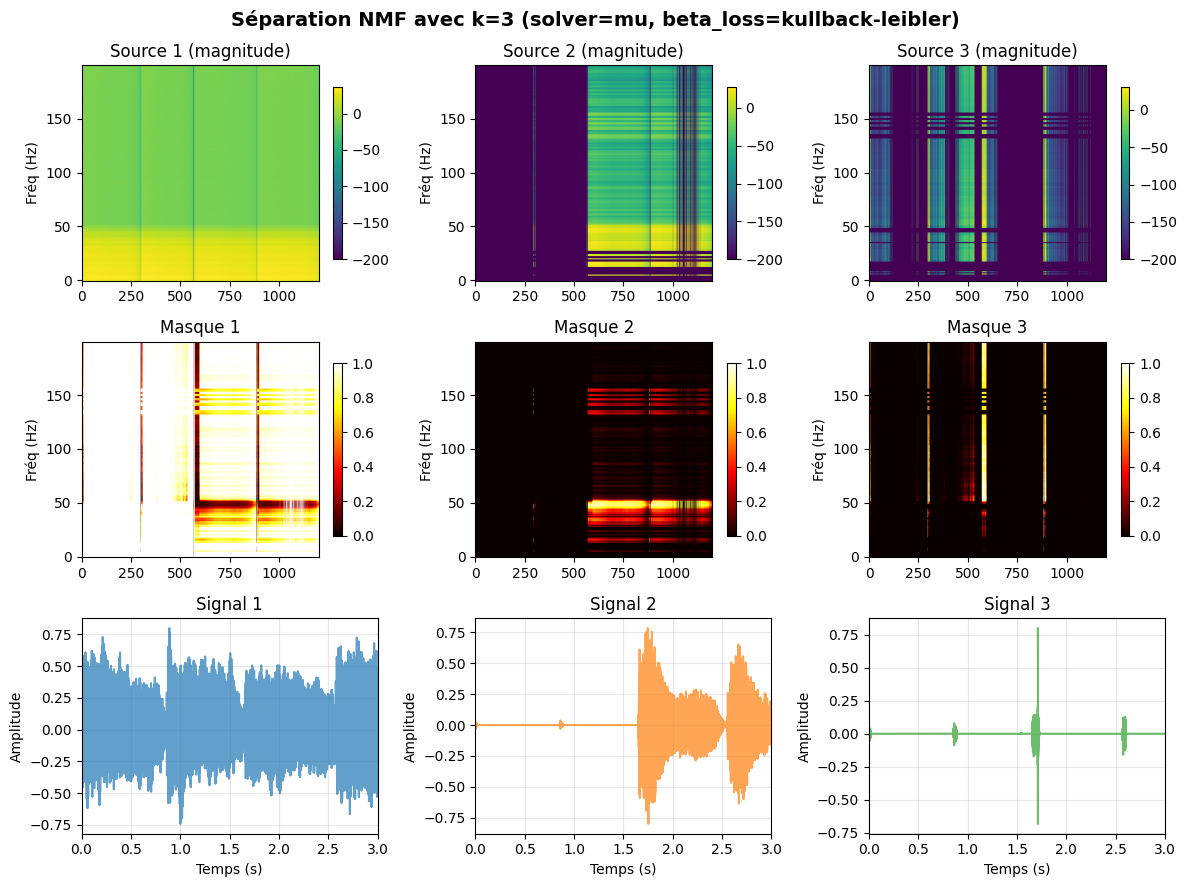


ANALYSE DES BASES SPECTRALES


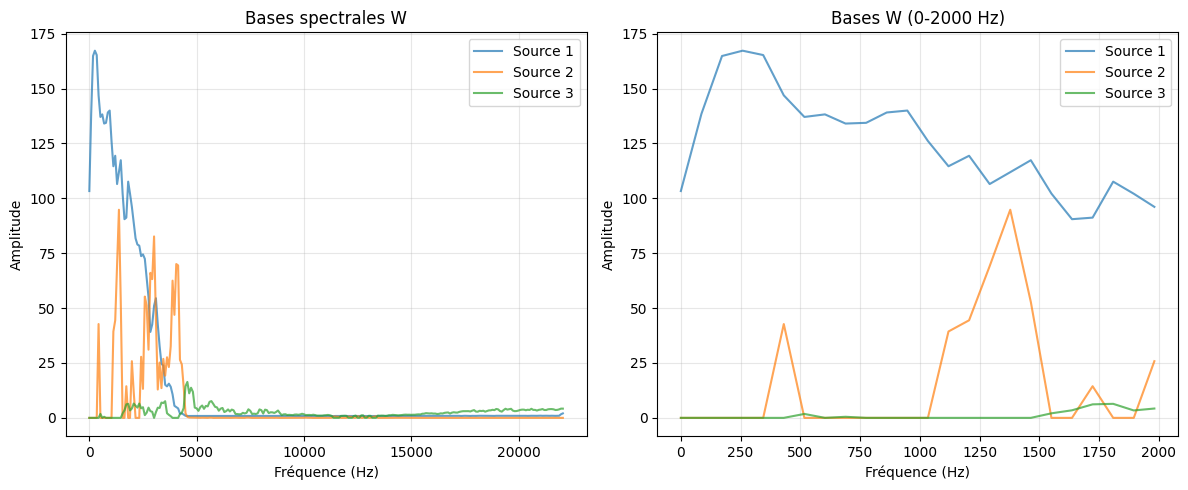


INSTRUCTIONS POUR L'ÉCOUTE

1. Écoute les fichiers dans le dossier: separated_k3/
2. Commence par 'mixture_reconstructed.wav' (devrait ressembler à l'original)
3. Écoute chaque source séparément (source_1.wav, source_2.wav, etc.)
4. Compare avec le fichier original

Signes d'une bonne séparation:
- Chaque source contient des éléments distincts
- La somme des sources ≈ le mélange original
- Les sources sont 'musicalement cohérentes'

Si la séparation n'est pas bonne:
1. Essayer k=2 ou k=5
2. Changer beta_loss='frobenius' (au lieu de 'kullback-leibler')
3. Prétraiter le signal (normalisation différente)
4. Implémenter Griffin-Lim pour la phase



In [135]:
# -------------------------------------------------
# SÉPARATION AVEC ESTIMATION DE PHASE - VERSION CORRIGÉE
# -------------------------------------------------
print("=" * 70)
print("SÉPARATION AVEC ESTIMATION DE PHASE AMÉLIORÉE")
print("=" * 70)

# 1. Utiliser NMF avec compression logarithmique (meilleur pour audio)
def NMF_log_compression(V, k=3, max_iter=300):
    """NMF avec compression logarithmique pour audio."""
    # Compression logarithmique
    V_log = np.log1p(V * 100)  # log(1 + 100*V)
    V_log = V_log / V_log.max()
    
    # NMF avec solver='mu' pour Kullback-Leibler
    model = SklearnNMF(
        n_components=k,
        init='nndsvd',
        solver='mu',  # IMPORTANT: solver mu pour Kullback-Leibler
        max_iter=max_iter,
        tol=1e-4,
        random_state=42,
        beta_loss='kullback-leibler'  # Meilleur pour audio
    )
    
    print(f"  Entraînement NMF avec k={k}, solver='mu', beta_loss='kullback-leibler'...")
    W = model.fit_transform(V_log)
    H = model.components_
    
    print(f"  ✓ NMF terminé: erreur={model.reconstruction_err_:.4f}, itérations={model.n_iter_}")
    
    # Reconvertir à l'échelle originale
    W = W * V.max()
    
    return W, H, model

# 2. Test avec différentes valeurs de k
print("\nTest avec différentes valeurs de k:")
k_values = [2, 3, 4, 5]
results = {}

for k in k_values:
    print(f"\nk={k}:")
    try:
        W_k, H_k, model_k = NMF_log_compression(M_mag_our, k=k, max_iter=200)
        V_reconstructed = W_k @ H_k
        
        # Calculer l'erreur de reconstruction sur les données originales
        reconstruction_error = np.linalg.norm(M_mag_our - V_reconstructed, 'fro') ** 2
        
        results[k] = {
            'W': W_k,
            'H': H_k,
            'model': model_k,
            'error': reconstruction_error
        }
        
        print(f"  Erreur reconstruction: {reconstruction_error:.4f}")
        
    except Exception as e:
        print(f"  ✗ Erreur avec k={k}: {e}")

# 3. Choisir le meilleur k
if results:
    best_k = min(results.keys(), key=lambda k: results[k]['error'])
    print(f"\nMeilleur k: {best_k} (erreur: {results[best_k]['error']:.4f})")
    
    W_best = results[best_k]['W']
    H_best = results[best_k]['H']
    
    # 4. Séparer les sources (magnitude seulement)
    print(f"\nSéparation des {best_k} sources...")
    sources_mag = []
    for i in range(best_k):
        source_i_mag = W_best[:, i:i+1] @ H_best[i:i+1, :]
        sources_mag.append(source_i_mag)
        print(f"  Source {i+1}: max={source_i_mag.max():.4f}, mean={source_i_mag.mean():.4f}")
    
    # 5. Méthode SIMPLE pour l'estimation de phase
    print(f"\nEstimation de phase (méthode simple)...")
    sources_complex = []
    
    # Calculer le masque de Wiener pour chaque source
    V_total = np.sum(sources_mag, axis=0) + 1e-10
    
    for i in range(best_k):
        print(f"  Source {i+1}...")
        
        # Masque de Wiener: proportion de l'énergie de la source
        mask_i = sources_mag[i] / V_total
        
        # Phase estimée = phase du mélange × masque + bruit × (1-masque)
        phase_mix = phase_original  # Phase du mélange complet
        phase_noise = np.random.randn(*phase_mix.shape) * 0.05  # Un peu de bruit
        phase_i = phase_mix * mask_i + phase_noise * (1 - mask_i)
        
        # Créer STFT complexe
        source_complex = sources_mag[i] * np.exp(1j * phase_i)
        sources_complex.append(source_complex)
    
    # 6. Reconstruction audio
    print(f"\nReconstruction audio...")
    separated_signals = []
    
    for i in range(best_k):
        print(f"  Source {i+1}...")
        try:
            t_i, signal_i = reconstruct_audio_from_stft(
                sources_complex[i], fs, nperseg, noverlap, window
            )
            # Normaliser
            if len(signal_i) > 0:
                signal_i = signal_i / np.max(np.abs(signal_i)) * 0.8
            separated_signals.append(signal_i)
            print(f"    ✓ {len(signal_i)} échantillons ({len(signal_i)/fs:.2f}s)")
        except Exception as e:
            print(f"    ✗ Erreur: {e}")
            separated_signals.append(None)
    
    # 7. Sauvegarde
    print(f"\n{'='*50}")
    print("SAUVEGARDE")
    print(f"{'='*50}")
    
    output_dir = f"separated_k{best_k}"
    os.makedirs(output_dir, exist_ok=True)
    
    # Sauvegarder chaque source
    for i in range(best_k):
        if separated_signals[i] is not None:
            path = os.path.join(output_dir, f"source_{i+1}.wav")
            # Convertir en int16
            signal_int16 = np.int16(separated_signals[i] * 32767)
            scipy.io.wavfile.write(path, fs, signal_int16)
            print(f"✓ Source {i+1}: {path}")
    
    # Sauvegarder le mélange reconstruit (somme des sources)
    if all(s is not None for s in separated_signals):
        # Trouver longueur commune
        min_len = min(len(s) for s in separated_signals)
        signals_truncated = [s[:min_len] for s in separated_signals]
        
        # Somme
        mixture_recon = np.sum(signals_truncated, axis=0)
        mixture_recon = mixture_recon / np.max(np.abs(mixture_recon)) * 0.8
        
        path = os.path.join(output_dir, "mixture_reconstructed.wav")
        scipy.io.wavfile.write(path, fs, np.int16(mixture_recon * 32767))
        print(f"✓ Mélange reconstruit: {path}")
    
    # 8. Visualisation
    print(f"\n{'='*50}")
    print("VISUALISATION")
    print(f"{'='*50}")
    
    n_cols = min(best_k, 4)
    n_rows = 3
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows))
    
    # Ligne 1: Magnitude des sources
    for i in range(min(best_k, n_cols)):
        ax = axes[0, i] if n_cols > 1 else axes[0]
        im = ax.imshow(20 * np.log10(sources_mag[i][:200] + 1e-10), 
                      aspect='auto', origin='lower', cmap='viridis')
        ax.set_title(f'Source {i+1} (magnitude)')
        ax.set_ylabel('Fréq (Hz)')
        plt.colorbar(im, ax=ax, shrink=0.8)
    
    # Ligne 2: Masques de Wiener
    for i in range(min(best_k, n_cols)):
        ax = axes[1, i] if n_cols > 1 else axes[1]
        mask_i = sources_mag[i] / (V_total + 1e-10)
        im = ax.imshow(mask_i[:200], aspect='auto', origin='lower', 
                      cmap='hot', vmin=0, vmax=1)
        ax.set_title(f'Masque {i+1}')
        ax.set_ylabel('Fréq (Hz)')
        plt.colorbar(im, ax=ax, shrink=0.8)
    
    # Ligne 3: Signaux temporels
    for i in range(min(best_k, n_cols)):
        ax = axes[2, i] if n_cols > 1 else axes[2]
        if separated_signals[i] is not None:
            time_axis = np.arange(len(separated_signals[i])) / fs
            ax.plot(time_axis, separated_signals[i], color=f'C{i}', alpha=0.7)
            ax.set_title(f'Signal {i+1}')
            ax.set_xlabel('Temps (s)')
            ax.set_ylabel('Amplitude')
            ax.grid(True, alpha=0.3)
            ax.set_xlim([0, min(3, time_axis[-1])])
    
    plt.suptitle(f'Séparation NMF avec k={best_k} (solver=mu, beta_loss=kullback-leibler)', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 9. Analyse des bases spectrales
    print(f"\n{'='*50}")
    print("ANALYSE DES BASES SPECTRALES")
    print(f"{'='*50}")
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Bases spectrales W
    ax1 = axes[0]
    for i in range(best_k):
        ax1.plot(freqs_our, W_best[:, i], label=f'Source {i+1}', alpha=0.7)
    ax1.set_title('Bases spectrales W')
    ax1.set_xlabel('Fréquence (Hz)')
    ax1.set_ylabel('Amplitude')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Zoom sur basses fréquences
    ax2 = axes[1]
    freq_mask = freqs_our <= 2000
    for i in range(best_k):
        ax2.plot(freqs_our[freq_mask], W_best[freq_mask, i], 
                label=f'Source {i+1}', alpha=0.7)
    ax2.set_title('Bases W (0-2000 Hz)')
    ax2.set_xlabel('Fréquence (Hz)')
    ax2.set_ylabel('Amplitude')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 10. Conclusion
    print(f"\n{'='*70}")
    print("INSTRUCTIONS POUR L'ÉCOUTE")
    print(f"{'='*70}")
    
    print(f"\n1. Écoute les fichiers dans le dossier: {output_dir}/")
    print(f"2. Commence par 'mixture_reconstructed.wav' (devrait ressembler à l'original)")
    print(f"3. Écoute chaque source séparément (source_1.wav, source_2.wav, etc.)")
    print(f"4. Compare avec le fichier original")
    
    print(f"\nSignes d'une bonne séparation:")
    print("- Chaque source contient des éléments distincts")
    print("- La somme des sources ≈ le mélange original")
    print("- Les sources sont 'musicalement cohérentes'")
    
    print(f"\nSi la séparation n'est pas bonne:")
    print("1. Essayer k=2 ou k=5")
    print("2. Changer beta_loss='frobenius' (au lieu de 'kullback-leibler')")
    print("3. Prétraiter le signal (normalisation différente)")
    print("4. Implémenter Griffin-Lim pour la phase")

else:
    print("✗ Aucun résultat NMF disponible!")

print(f"\n{'='*70}")